# Boreas-RT | Four-sensor measurements, calibration, and independent LiDAR odometry

**Sequence:** `boreas-2024-12-03-12-54`  
**IMUs:** infilled DMU41 and Aeva IMU  
**LiDARs:** Velodyne Alpha-Prime and Aeva Aeries II

This notebook uses the actual `boreas_dataset` package provided with the repository. It loads both IMUs, visualizes a sample raw scan from each LiDAR, constructs a **four-sensor 3D extrinsic diagram**, and evaluates **independent scan-registration odometry** from the files `lidar_odometry_velodyne.csv` and `lidar_odometry_aeva.csv` against `sequence.lidar_poses(source=...)`.

**Geometric convention.** A matrix `T_A_B` transforms coordinates from frame **B** into frame **A**. Each odometry increment is `T_previous_current`; integration is `T_0_k = T_0_(k−1) @ T_(k−1)_k`. The resulting path is anchored to its first **reference** pose **once**. There is **no global alignment, registration to ground truth, or re-anchoring** later in the sequence. The difference between paths is accumulated drift. Reference sensor poses come from Applanix/GNSS/INS and are **not** independent scan odometry.

**Limitations.** The raw point clouds are not deskewed; Aeva point times retain their raw stored units. The examples visualize only bounded point subsets. Missing odometry CSVs are reported and skipped; ICP is not run automatically in the notebook.

## 0. Imports and plotting style
Run the notebook from the repository root or `src/boreas_dataset/notebooks`. An editable package installation also works.

In [1]:
from pathlib import Path
import os
import sys

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "src" / "boreas_dataset" / "dataset.py").is_file():
        sys.path.insert(0, str(candidate / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial.transform import Rotation
from IPython.display import display

from boreas_dataset.dataset import BoreasDataset
from boreas_dataset.calibration import validate_rigid_transform
from boreas_dataset.lidar import LIDAR_SOURCES, motion_magnitudes
from boreas_dataset.odometry import load_lidar_data_csv
from boreas_dataset.sensor_statistics import imu_statistics
from boreas_dataset.timing import relative_seconds, timestamp_statistics, timestamps_to_ns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 180,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "font.size": 10, "legend.frameon": True})
AXIS_COLORS = ("#2778b7", "#dc7d36", "#31855c")
SENSOR_COLORS = {"velodyne": "#2778b7", "aeva": "#b354a1",
                 "dmu_infilled": "#31855c", "aeva_imu": "#dc7d36"}

## 1. Configuration
`DATA_ROOT` can be the parent directory of the sequence or the sequence directory itself. Use `BOREAS_DATA_ROOT` to override it. `TIME_START`/`TIME_END` are optional **absolute UTC seconds**. The IMU plotting decimation affects figures only, not the loaded data or calculations.

In [2]:
DATA_ROOT = os.environ.get("BOREAS_DATA_ROOT")  # None uses the package's OS-dependent default
SEQUENCE_ID = "boreas-2024-12-03-12-54"
IMU_SOURCES = ("dmu_infilled", "aeva")
LIDAR_NAMES = ("velodyne", "aeva")
TIME_START = None
TIME_END = None

IMU_PLOT_MAX_SAMPLES = 30_000
SCAN_PLOT_MAX_POINTS = 25_000
SCAN_SAMPLE_FRACTION = 0.50  # representative scan, fractional position along recording
TRAJECTORY_PLOT_MAX_POINTS = 10_000
POSE_MATCH_TOLERANCE_S = 0.15     # acceptable nearest GT sample for interpolation
POSE_INTERPOLATION_MAX_GAP_S = 0.40
SHOW_PLOTS = True
SAVE_FIGURES = False
FIGURE_DIR = Path("outputs/plots/boreas_rt")


def finish_figure(fig, filename=None):
    fig.tight_layout()
    if SAVE_FIGURES and filename:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def plotting_indices(n, maximum=TRAJECTORY_PLOT_MAX_POINTS):
    return np.arange(n) if n <= maximum else np.unique(np.linspace(0, n - 1, maximum, dtype=int))


def relative_time(timestamps_ns, origin_ns):
    return relative_seconds(np.asarray(timestamps_ns, dtype=np.int64), int(origin_ns))


def equal_axes_3d(ax, points, extra=0.1):
    xyz = np.asarray(points, dtype=float).reshape(-1, 3)
    span = np.ptp(xyz, axis=0)
    half_range = max(np.max(span) * (0.5 + extra), 0.5)
    midpoint = (xyz.max(axis=0) + xyz.min(axis=0)) * 0.5
    for setter, center in zip((ax.set_xlim, ax.set_ylim, ax.set_zlim), midpoint):
        setter(center - half_range, center + half_range)
    ax.set_box_aspect((1, 1, 1))


dataset = BoreasDataset(DATA_ROOT)
sequence = dataset.sequence(SEQUENCE_ID)
print("Sequence:", sequence.sequence_id)
print("Root:", sequence.root)
print("Detected sensors:", sequence.sensors)

Sequence: boreas-2024-12-03-12-54
Root: /mnt/d/Downloads/MobRobLab/BoreasDataset/boreas-2024-12-03-12-54
Detected sensors: {'imu': ['dmu', 'dmu_infilled', 'aeva', 'applanix'], 'lidar': ['velodyne', 'aeva'], 'detected_unimplemented': ['radar', 'camera']}


## 2. Availability, time coverage, and source conventions
The notebook requires both IMU CSVs, both LiDAR scan directories, and their `applanix/*_poses.csv` reference trajectories for complete plots. It can still visualize partial data if some components are absent.

**Important:** the Aeva LiDAR scan timestamp denotes scan start, while the Velodyne scan timestamp denotes scan midpoint. IMU timestamps are normalized to UTC seconds; for precise differences we use integer nanoseconds.

In [3]:
IMU_LABELS = {"dmu_infilled": "DMU41 (infilled)", "aeva": "Aeva IMU"}
LIDAR_LABELS = {"velodyne": "Velodyne", "aeva": "Aeva"}
rows = []
for source in IMU_SOURCES:
    path = sequence.root / ("imu/dmu_imu_infilled.csv" if source == "dmu_infilled" else "imu/aeva_imu.csv")
    rows.append({"sensor": IMU_LABELS[source], "kind": "IMU", "available": path.is_file(), "file": str(path.relative_to(sequence.root))})
for source in LIDAR_NAMES:
    folder = LIDAR_SOURCES[source][0]
    scans = sequence.lidar_scans(source=source) if source in sequence.sensors["lidar"] else []
    trajectory_path = sequence.root / "applanix" / f"{folder}_poses.csv"
    cache_path = sequence.root / f"lidar_odometry_{source}.csv"
    rows.append({"sensor": LIDAR_LABELS[source], "kind": "LiDAR", "available": bool(scans),
                 "file": f"{folder}/ ({len(scans):,} scans)"})
    rows.append({"sensor": f"{LIDAR_LABELS[source]} reference", "kind": "GT", "available": trajectory_path.is_file(),
                 "file": str(trajectory_path.relative_to(sequence.root))})
    rows.append({"sensor": f"{LIDAR_LABELS[source]} ICP", "kind": "Odometry cache", "available": cache_path.is_file(),
                 "file": str(cache_path.relative_to(sequence.root))})
display(pd.DataFrame(rows))

,sensor,kind,available,file
0,DMU41 (infilled),IMU,True,imu/dmu_imu_infilled.csv
1,Aeva IMU,IMU,True,imu/aeva_imu.csv
2,Velodyne,LiDAR,True,"lidar/ (9,480 scans)"
3,Velodyne reference,GT,True,applanix/lidar_poses.csv
4,Velodyne ICP,Odometry cache,True,lidar_odometry_velodyne.csv
5,Aeva,LiDAR,True,"aeva/ (9,860 scans)"
6,Aeva reference,GT,True,applanix/aeva_poses.csv
7,Aeva ICP,Odometry cache,True,lidar_odometry_aeva.csv


## 3. Both IMU streams: signals, norms, and acquisition gaps

Plot **native** measurements: each gyroscope and accelerometer axis, their magnitudes, and inter-sample intervals. No smoothing or coordinate reorientation is applied. Axis-by-axis comparisons of the two IMUs would require the extrinsics; their norms are directly comparable without rotating axes. Accelerometer readings include gravity.

In [4]:
imus = {}
imu_summary = []
for source in IMU_SOURCES:
    if source not in sequence.sensors["imu"]:
        print(f"Missing IMU {source}: skipping")
        continue
    data = sequence.imu(source, time_start=TIME_START, time_end=TIME_END)
    if len(data.timestamps_ns) < 2:
        print(f"Not enough measurements for {source} in selected interval")
        continue
    imus[source] = data
    stats = imu_statistics(data)
    imu_summary.append({"sensor": IMU_LABELS[source], "samples": stats["samples"],
                        "duration_s": stats["duration_s"], "median_rate_hz": stats["median_rate_hz"],
                        "gaps": stats["gaps"], "max_dt_ms": stats["max_dt_ms"],
                        "gyro_norm_p50_radps": stats["gyro_norm_p50_radps"],
                        "accel_norm_p50_mps2": stats["accel_norm_p50_mps2"]})
    print(f"{IMU_LABELS[source]}: frame={data.frame_id}, timestamps [{data.t_utc[0]:.6f}, {data.t_utc[-1]:.6f}] UTC s")
if imu_summary:
    display(pd.DataFrame(imu_summary).set_index("sensor").round(4))

DMU41 (infilled): frame=dmu, timestamps [1733248461.886083, 1733249447.843462] UTC s
Aeva IMU: frame=aeva_imu, timestamps [1733248441.387708, 1733249468.497708] UTC s


,samples,duration_s,median_rate_hz,gaps,max_dt_ms,gyro_norm_p50_radps,accel_norm_p50_mps2
sensor,,,,,,,
DMU41 (infilled),197195,985.9574,200.0026,0,4.9999,0.0262,9.8635
Aeva IMU,102711,1027.1100,100.0000,2,22.0270,0.0291,9.9401


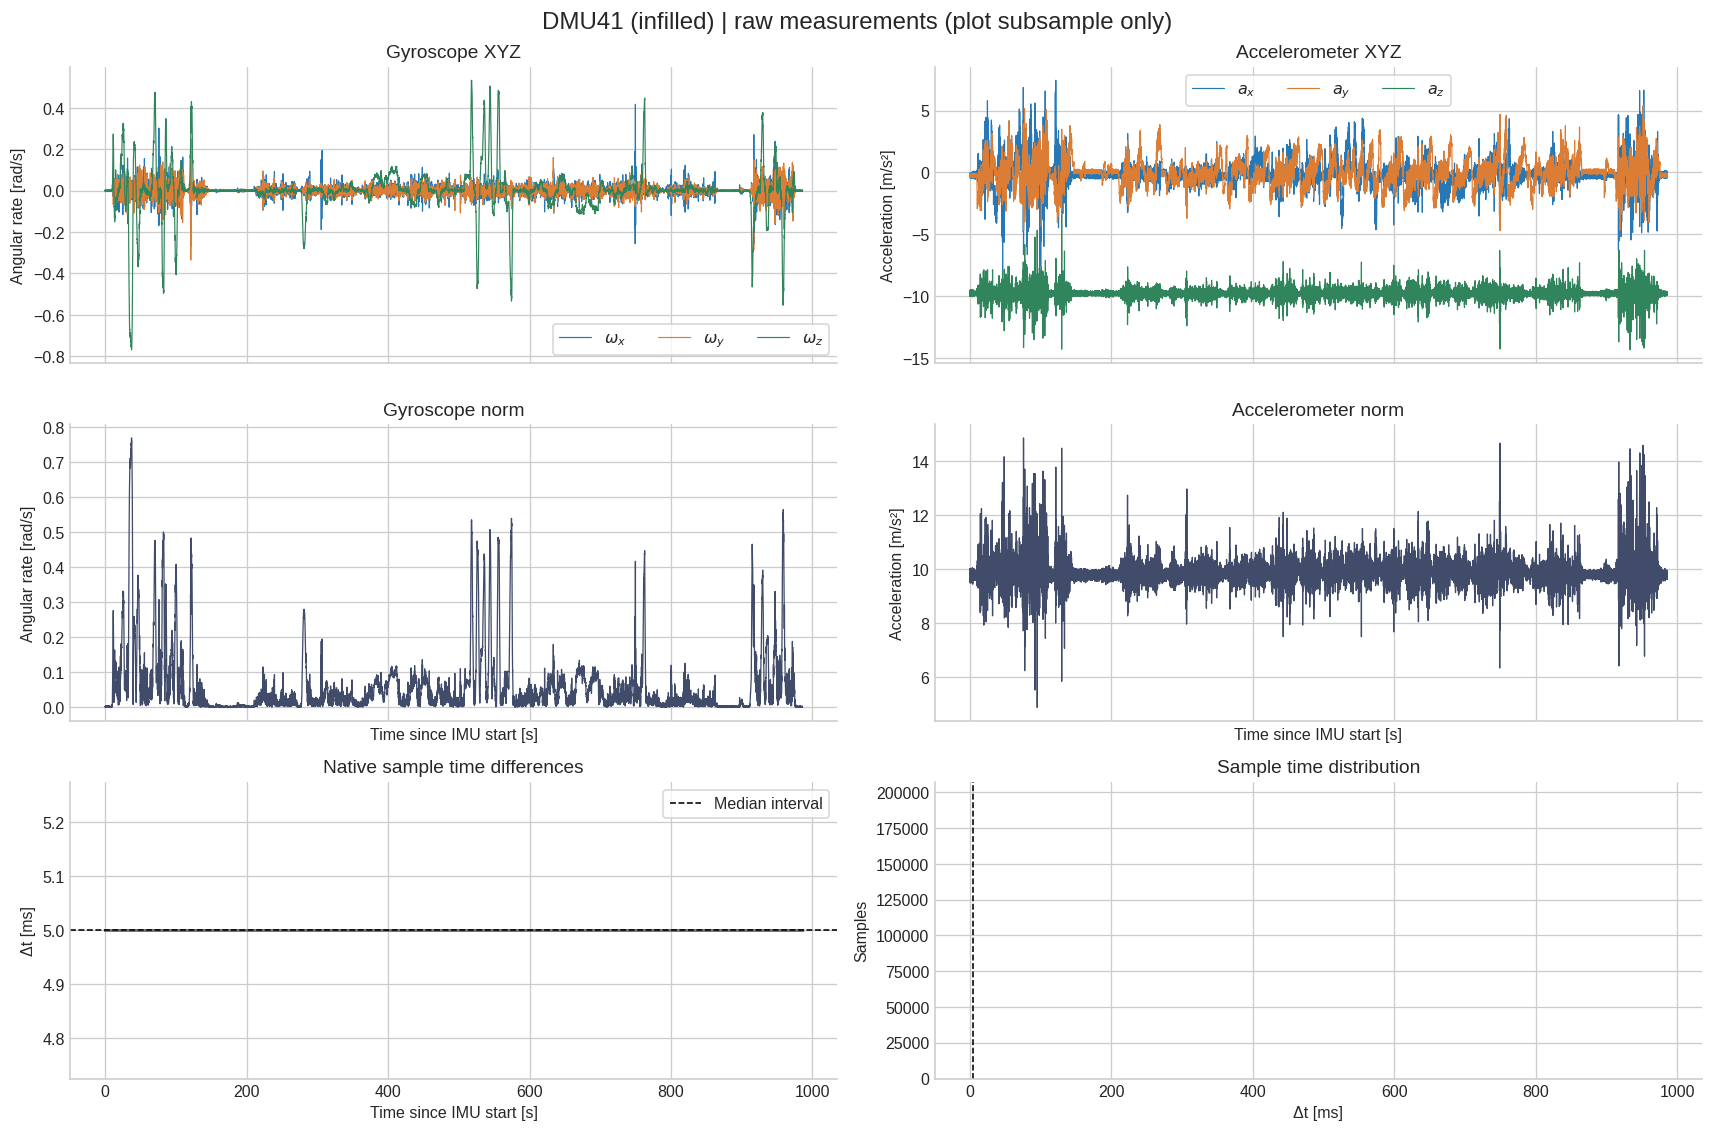

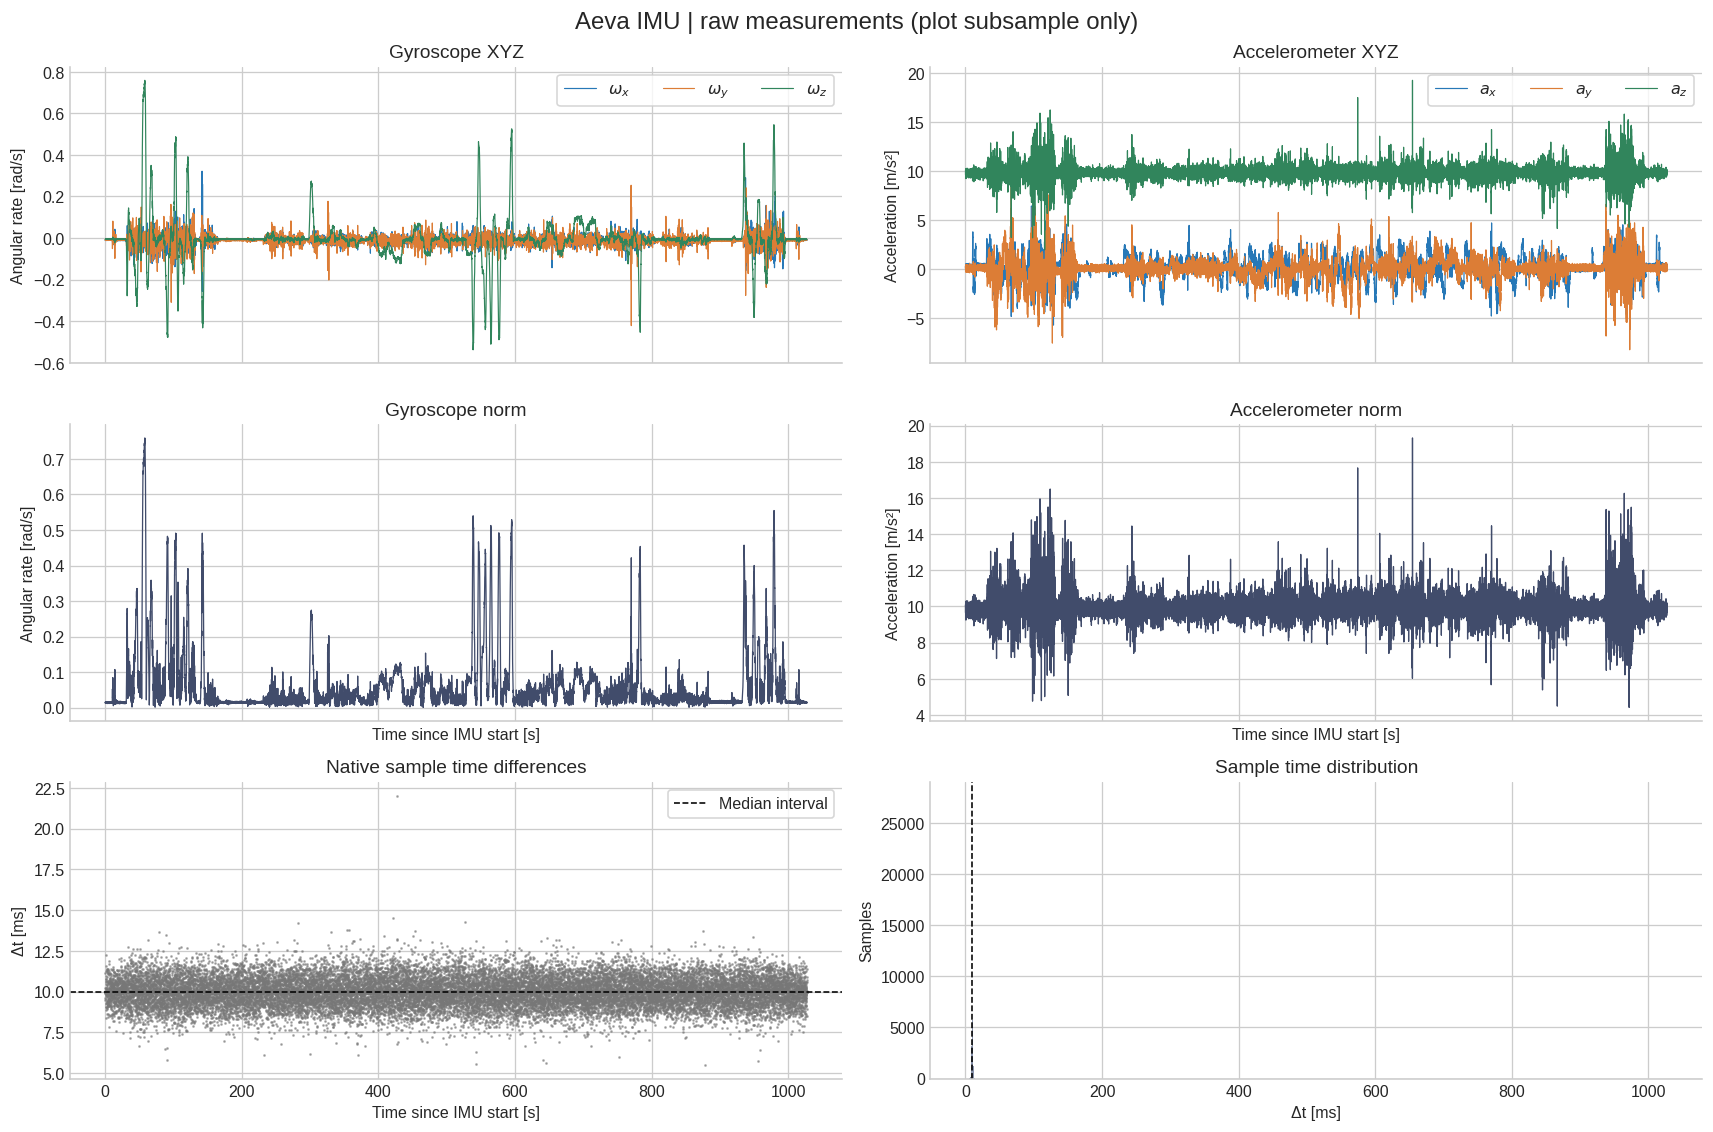

In [5]:
for source, imu in imus.items():
    indices = plotting_indices(len(imu.timestamps_ns), IMU_PLOT_MAX_SAMPLES)
    t = relative_time(imu.timestamps_ns[indices], imu.timestamps_ns[0])
    fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex="col")
    for axis, (letter, color) in enumerate(zip("xyz", AXIS_COLORS)):
        axes[0, 0].plot(t, imu.gyro_radps[indices, axis], color=color, lw=0.75, label=rf"$\omega_{letter}$")
        axes[0, 1].plot(t, imu.accel_mps2[indices, axis], color=color, lw=0.75, label=rf"$a_{letter}$")
    gyro_norm = np.linalg.norm(imu.gyro_radps[indices], axis=1)
    accel_norm = np.linalg.norm(imu.accel_mps2[indices], axis=1)
    axes[1, 0].plot(t, gyro_norm, color="#414c6b", lw=0.8)
    axes[1, 1].plot(t, accel_norm, color="#414c6b", lw=0.8)
    dt = np.diff(imu.timestamps_ns).astype(float) * 1e-9
    dt_idx = plotting_indices(len(dt), IMU_PLOT_MAX_SAMPLES)
    t_dt = relative_time(imu.timestamps_ns[1:][dt_idx], imu.timestamps_ns[0])
    axes[2, 0].plot(t_dt, dt[dt_idx] * 1e3, ".", ms=1.5, alpha=0.55, color="#777777")
    median_dt = float(np.median(dt))
    axes[2, 0].axhline(median_dt * 1e3, ls="--", color="black", lw=1.0, label="Median interval")
    axes[2, 0].legend()
    axes[2, 1].hist(dt * 1e3, bins=100, color="#8b95ae")
    axes[2, 1].axvline(median_dt * 1e3, color="black", ls="--", lw=1.0)
    axes[0, 0].set(title="Gyroscope XYZ", ylabel="Angular rate [rad/s]")
    axes[0, 1].set(title="Accelerometer XYZ", ylabel="Acceleration [m/s²]")
    axes[1, 0].set(title="Gyroscope norm", ylabel="Angular rate [rad/s]")
    axes[1, 1].set(title="Accelerometer norm", ylabel="Acceleration [m/s²]")
    axes[2, 0].set(title="Native sample time differences", xlabel="Time since IMU start [s]", ylabel="Δt [ms]")
    axes[2, 1].set(title="Sample time distribution", xlabel="Δt [ms]", ylabel="Samples")
    axes[0, 0].legend(ncol=3)
    axes[0, 1].legend(ncol=3)
    axes[1, 0].set_xlabel("Time since IMU start [s]")
    axes[1, 1].set_xlabel("Time since IMU start [s]")
    fig.suptitle(f"{IMU_LABELS[source]} | raw measurements (plot subsample only)", fontsize=15)
    finish_figure(fig, f"imu_{source}.png")

### 3.1. IMU-to-IMU timing and norm comparison
Both streams are plotted against the **same UTC origin**, without assuming equal frequencies or the same sensor axes. Observe differing sample rates and potential signal gaps; the infilled DMU signal is *resampled data*, not the raw DMU sensor output.

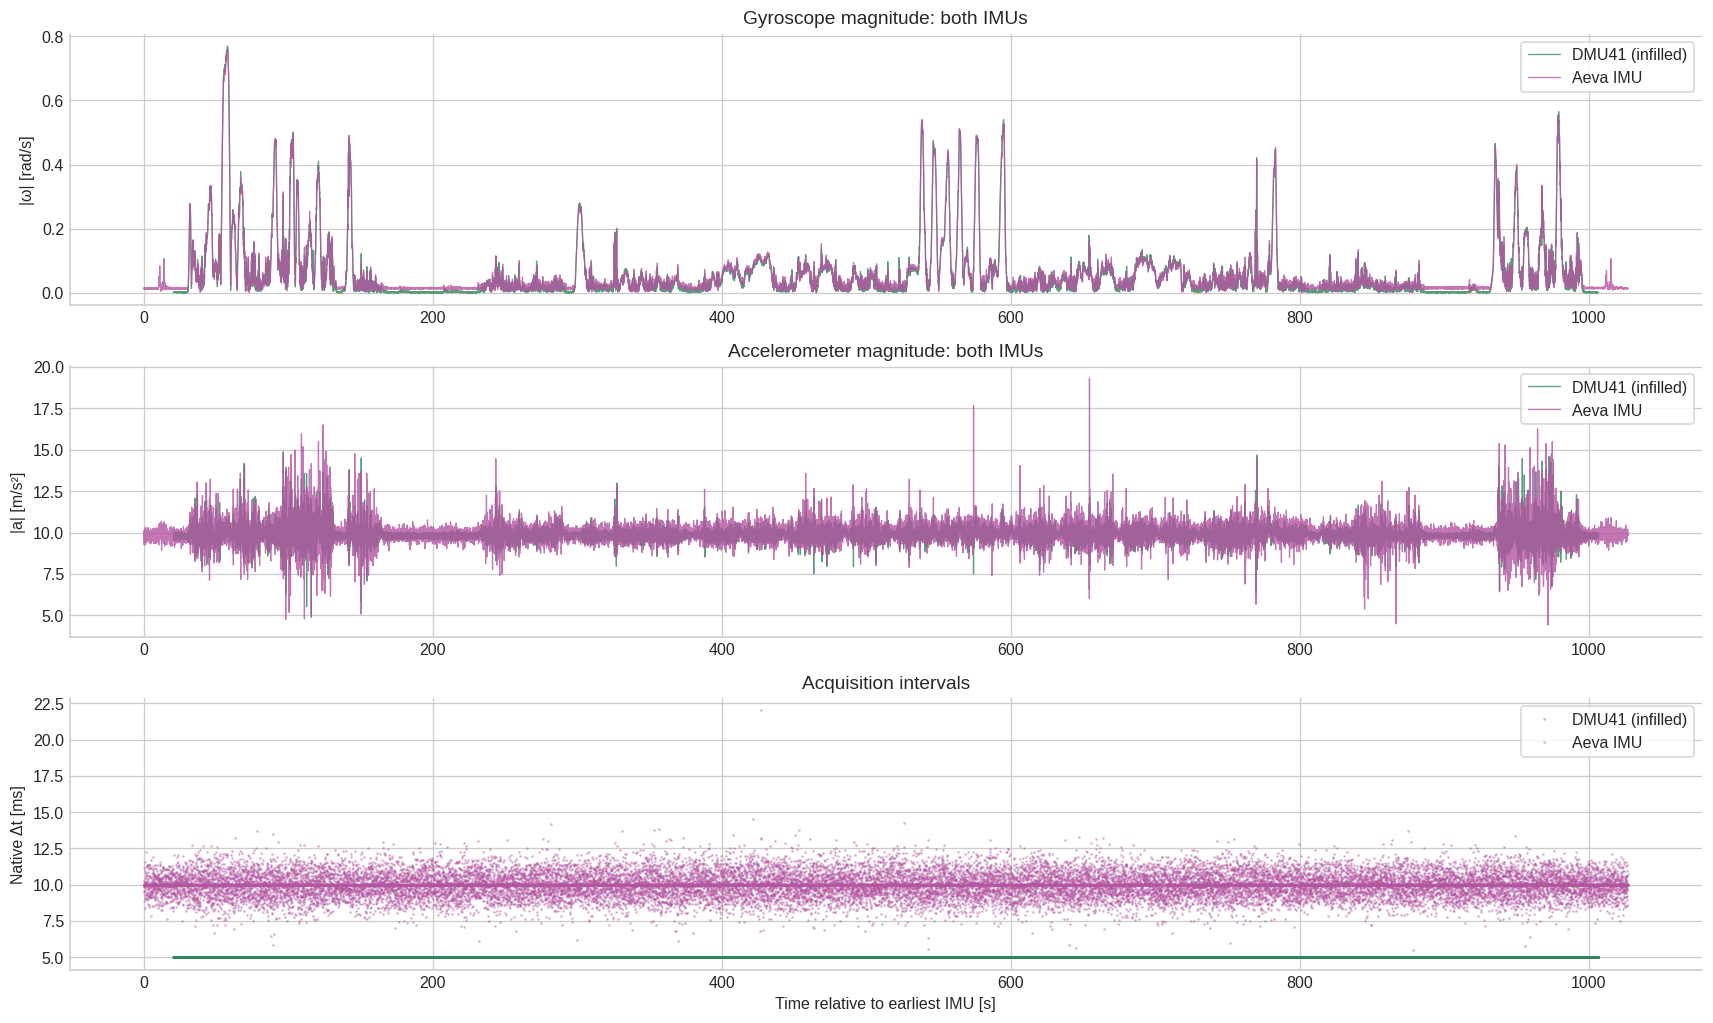

In [6]:
if imus:
    origin_ns = min(data.timestamps_ns[0] for data in imus.values())
    fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=False)
    for source, imu in imus.items():
        idx = plotting_indices(len(imu.timestamps_ns), IMU_PLOT_MAX_SAMPLES)
        t = relative_time(imu.timestamps_ns[idx], origin_ns)
        color = SENSOR_COLORS[source]
        axes[0].plot(t, np.linalg.norm(imu.gyro_radps[idx], axis=1), lw=0.8, alpha=0.80,
                     label=IMU_LABELS[source], color=color)
        axes[1].plot(t, np.linalg.norm(imu.accel_mps2[idx], axis=1), lw=0.8, alpha=0.80,
                     label=IMU_LABELS[source], color=color)
        dt = np.diff(imu.timestamps_ns) * 1e-9
        idx_dt = plotting_indices(len(dt), IMU_PLOT_MAX_SAMPLES)
        axes[2].plot(relative_time(imu.timestamps_ns[1:][idx_dt], origin_ns), dt[idx_dt] * 1e3,
                     ".", ms=1.5, alpha=0.35, label=IMU_LABELS[source], color=color)
    axes[0].set(ylabel="|ω| [rad/s]", title="Gyroscope magnitude: both IMUs")
    axes[1].set(ylabel="|a| [m/s²]", title="Accelerometer magnitude: both IMUs")
    axes[2].set(xlabel="Time relative to earliest IMU [s]", ylabel="Native Δt [ms]", title="Acquisition intervals")
    for ax in axes:
        ax.legend()
    finish_figure(fig, "both_imu_norms_timing.png")

## 4. Both raw LiDAR sensors: representative scans
Each sensor gets a 3D cloud, a top-down intensity view, a range histogram, and a scan-property histogram. These are **actual points** read from the stored binary files. Aeva contains radial velocity (Doppler); Velodyne does not. Aeva's stored point-time field is deliberately not converted here.

In [7]:
lidar_scans = {}
for source in LIDAR_NAMES:
    if source not in sequence.sensors["lidar"]:
        print(f"Missing {source} scan directory; skipping raw scan plots")
        continue
    entries = sequence.lidar_scans(source=source, time_start=TIME_START, time_end=TIME_END)
    if not entries:
        print(f"No {source} scans in selected time interval")
        continue
    lidar_scans[source] = entries
    stats = timestamp_statistics(np.array([s.timestamp_ns for s in entries], dtype=np.int64))
    print(f"{LIDAR_LABELS[source]}: {len(entries):,} scans, "
          f"median frequency {stats['frequency_hz']:.2f} Hz, "
          f"timestamp reference: {entries[0].timestamp_reference}")

Velodyne: 9,480 scans, median frequency 9.64 Hz, timestamp reference: midpoint
Aeva: 9,860 scans, median frequency 10.00 Hz, timestamp reference: start


velodyne: 1733248954630783.bin: 211,998 raw points, 25,000 displayed
  XYZ min/max [m]: [-138.78073   -137.9999      -2.9766238] / [169.16783 167.79976  28.53671]


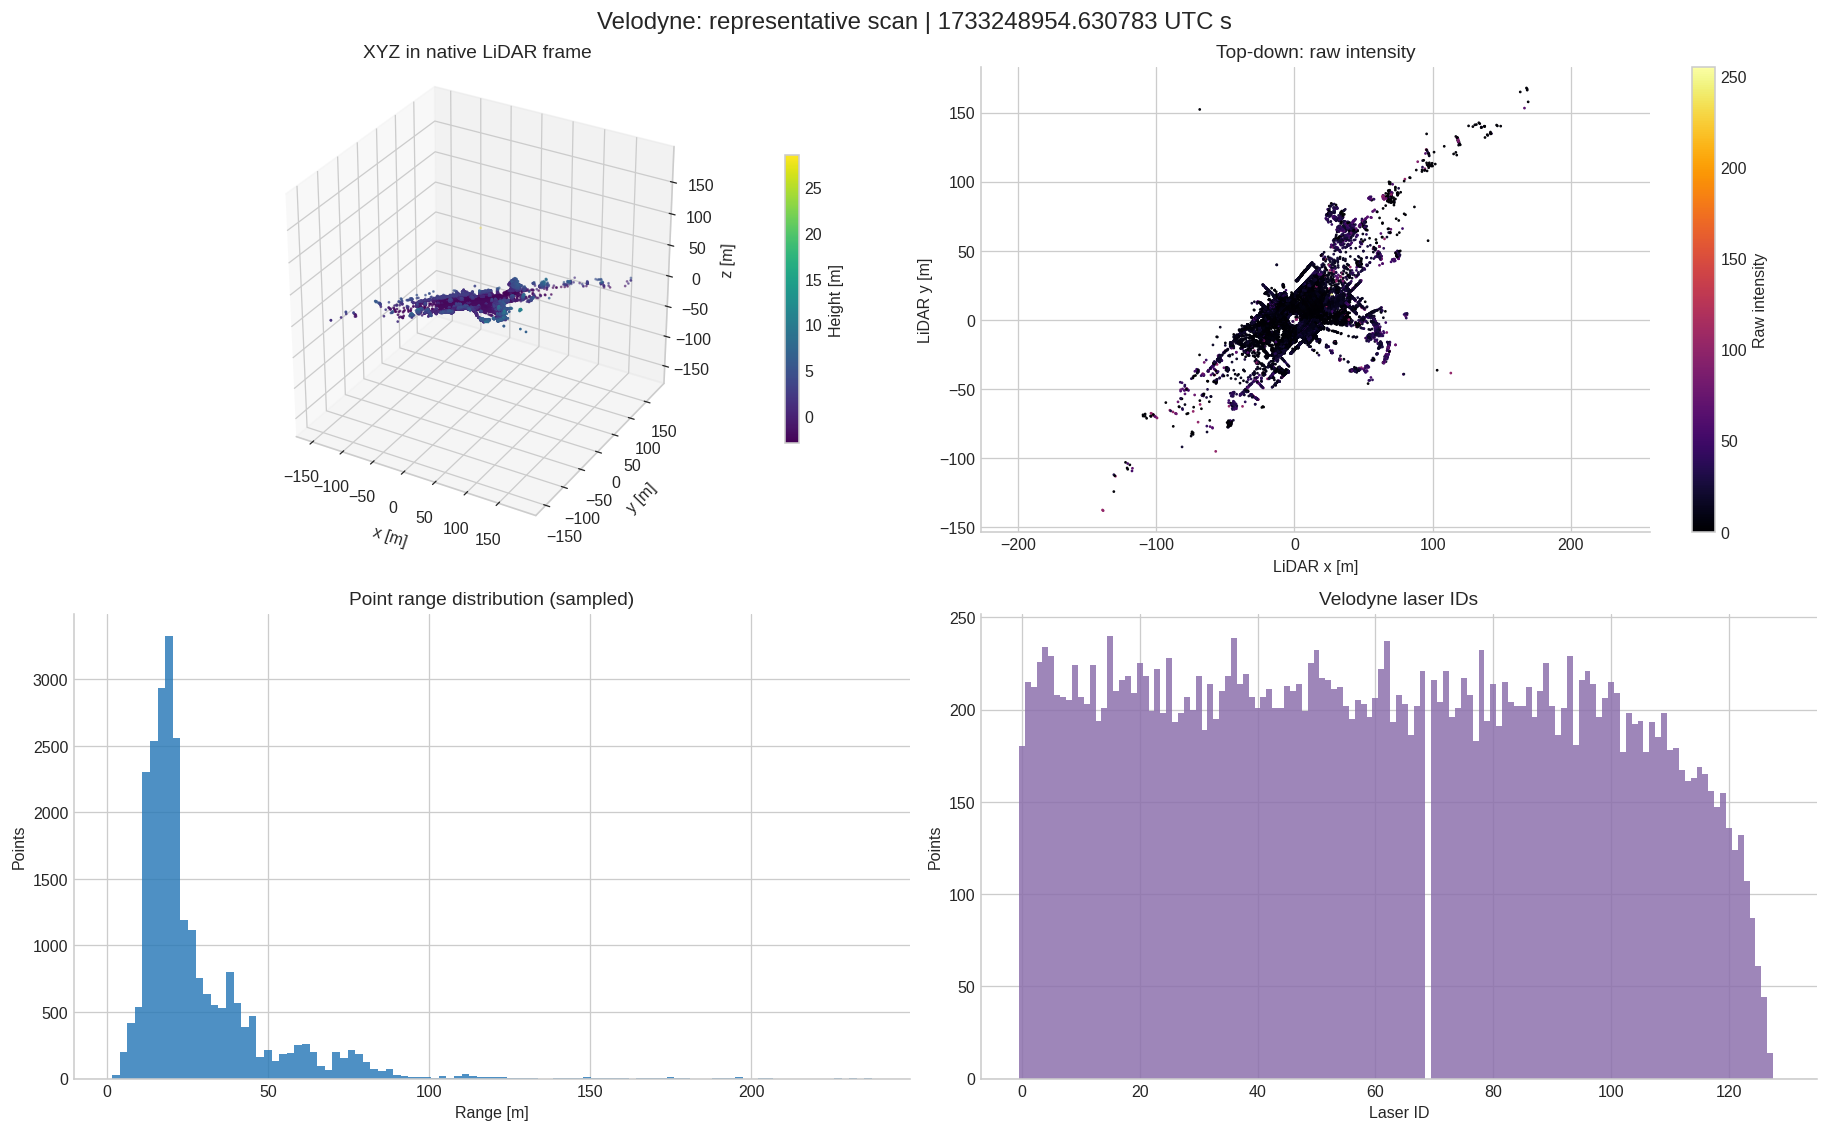

aeva: 1733248954799580.bin: 106,671 raw points, 25,000 displayed
  XYZ min/max [m]: [  4.662089 -57.62291   -3.289164] / [192.44772   39.246094   8.86484 ]


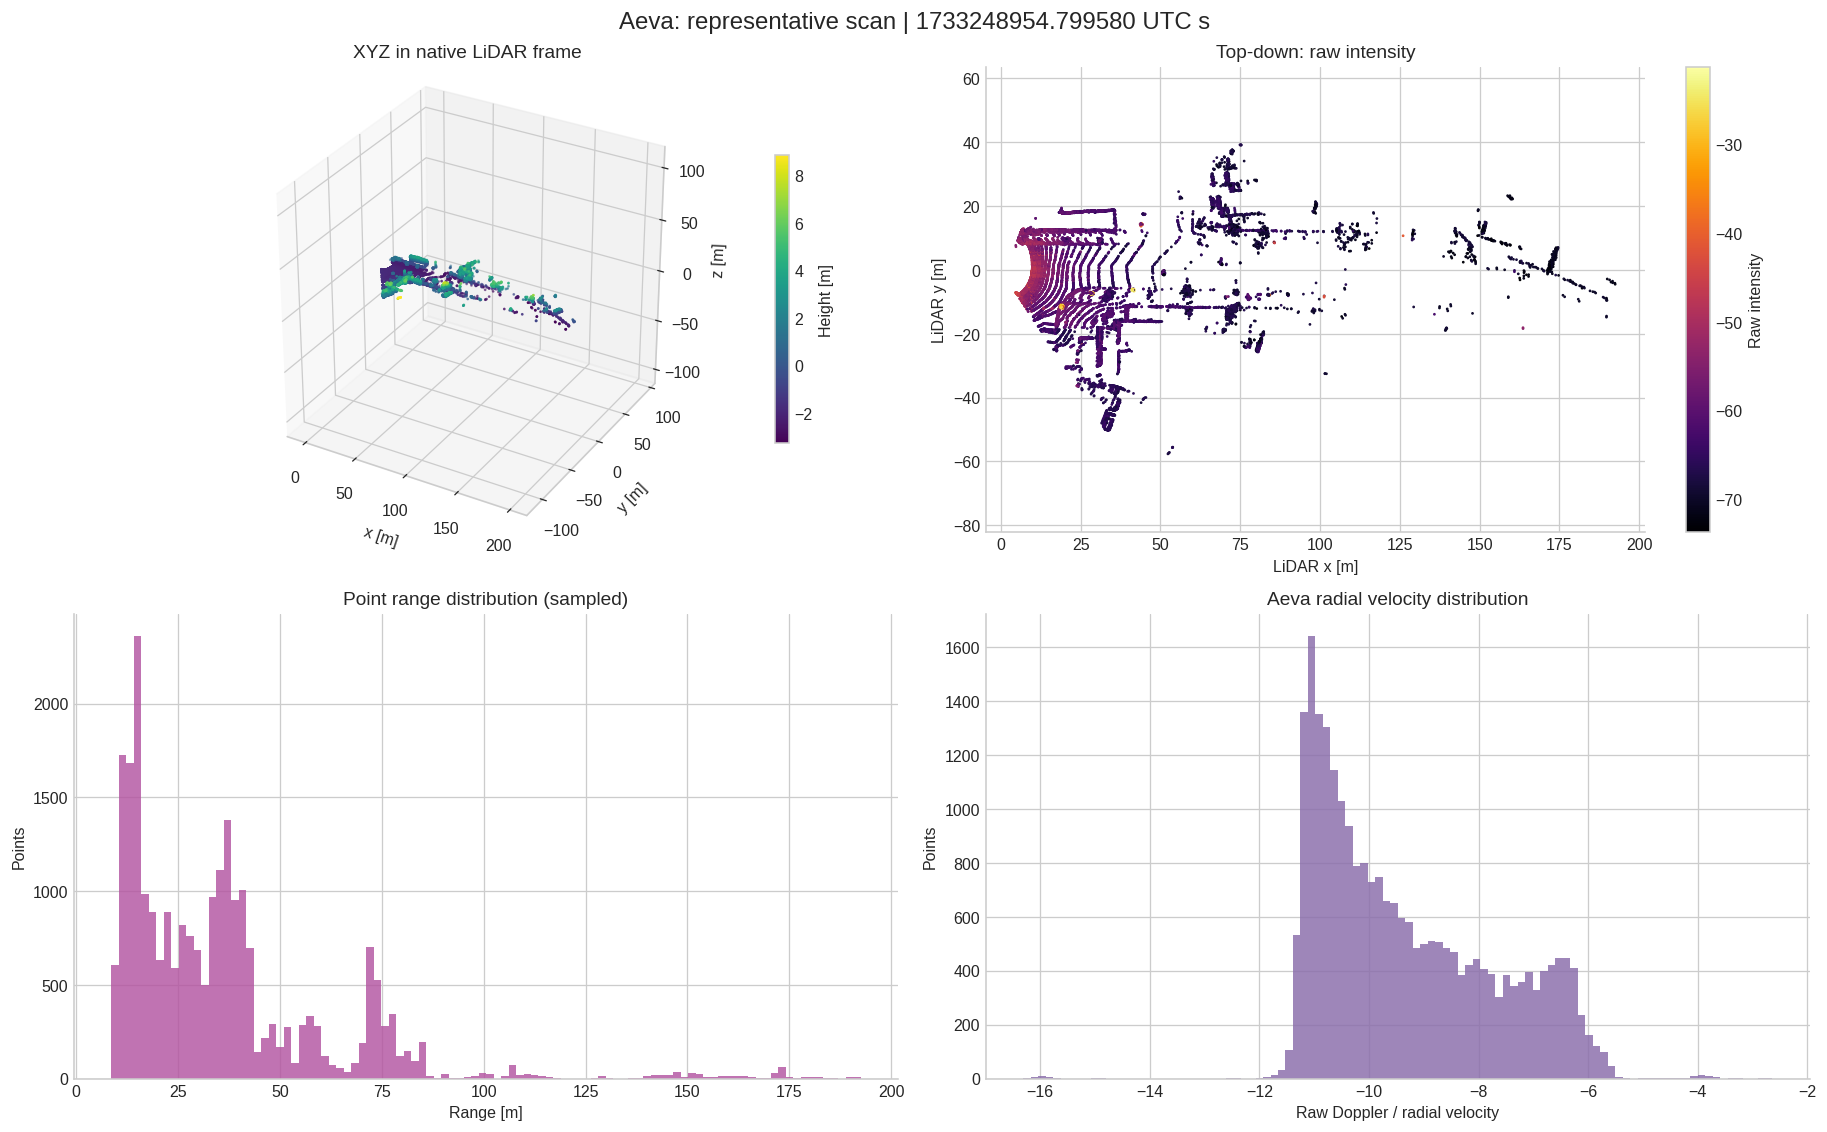

In [8]:
for source, scans in lidar_scans.items():
    chosen = scans[min(int((len(scans) - 1) * SCAN_SAMPLE_FRACTION), len(scans) - 1)]
    points = chosen.load(max_points=SCAN_PLOT_MAX_POINTS)
    xyz = points[:, :3]
    intensity_col = 3 if source == "velodyne" else 4
    ranges_m = np.linalg.norm(xyz, axis=1)
    total_points = chosen.path.stat().st_size // (4 * LIDAR_SOURCES[source][1])
    print(f"{source}: {chosen.path.name}: {total_points:,} raw points, {len(points):,} displayed")
    print(f"  XYZ min/max [m]: {xyz.min(axis=0)} / {xyz.max(axis=0)}")
    fig = plt.figure(figsize=(16, 10))
    grid = fig.add_gridspec(2, 2)
    ax3 = fig.add_subplot(grid[0, 0], projection="3d")
    xy = fig.add_subplot(grid[0, 1])
    hist_range = fig.add_subplot(grid[1, 0])
    hist_feature = fig.add_subplot(grid[1, 1])
    cloud = ax3.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2], c=xyz[:, 2], s=0.5, cmap="viridis", rasterized=True)
    ax3.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title="XYZ in native LiDAR frame")
    equal_axes_3d(ax3, xyz)
    fig.colorbar(cloud, ax=ax3, shrink=0.62, pad=0.09, label="Height [m]")
    dots = xy.scatter(xyz[:, 0], xyz[:, 1], c=points[:, intensity_col], s=0.5,
                      cmap="inferno", rasterized=True)
    xy.set(xlabel="LiDAR x [m]", ylabel="LiDAR y [m]", title="Top-down: raw intensity")
    xy.set_aspect("equal", adjustable="datalim")
    fig.colorbar(dots, ax=xy, label="Raw intensity")
    hist_range.hist(ranges_m, bins=100, color=SENSOR_COLORS[source], alpha=0.82)
    hist_range.set(title="Point range distribution (sampled)", xlabel="Range [m]", ylabel="Points")
    if source == "aeva":
        hist_feature.hist(points[:, 3], bins=100, color="#8a6dab", alpha=0.83)
        hist_feature.set(title="Aeva radial velocity distribution", xlabel="Raw Doppler / radial velocity", ylabel="Points")
    else:
        hist_feature.hist(points[:, 4], bins=np.arange(-0.5, 129.5, 1), color="#8a6dab", alpha=0.83)
        hist_feature.set(title="Velodyne laser IDs", xlabel="Laser ID", ylabel="Points")
    fig.suptitle(f"{LIDAR_LABELS[source]}: representative scan | {chosen.timestamp_s:.6f} UTC s", fontsize=15)
    finish_figure(fig, f"lidar_raw_{source}.png")

## 5. Sensor calibrations in a common 3D frame

**Extrinsic tree from Boreas-RT calibration files:**

- `T_applanix_lidar`: Velodyne LiDAR → Applanix
- `T_applanix_dmu`: DMU41 IMU → Applanix
- `T_aeva_lidar`: Velodyne LiDAR → Aeva LiDAR
- `T_imu_aeva`: Aeva LiDAR → Aeva internal IMU

Thus `T_applanix_aeva = T_applanix_lidar @ inv(T_aeva_lidar)` and `T_applanix_aeva_imu = T_applanix_aeva @ inv(T_imu_aeva)`.

The plot shows **positions and orthogonal coordinate axes** of each sensor with respect to Applanix, not calibration uncertainty. If a necessary matrix is unavailable, that sensor is **not** assigned a fabricated identity transform. The axis length is visual, and does not imply sensor size or accuracy.

In [9]:
calibrations = sequence.calibrations
print("Available matrices:", sorted(calibrations))
for name in ("T_applanix_lidar", "T_applanix_dmu", "T_aeva_lidar", "T_imu_aeva"):
    print(f"{name}: {'present' if name in calibrations else 'MISSING'}")

T_A_sensor = {"applanix": np.eye(4)}
if "T_applanix_lidar" in calibrations:
    T_A_sensor["velodyne"] = calibrations["T_applanix_lidar"]
if "T_applanix_dmu" in calibrations:
    T_A_sensor["dmu_infilled"] = calibrations["T_applanix_dmu"]
if "velodyne" in T_A_sensor and "T_aeva_lidar" in calibrations:
    T_A_sensor["aeva"] = T_A_sensor["velodyne"] @ np.linalg.inv(calibrations["T_aeva_lidar"])
if "aeva" in T_A_sensor and "T_imu_aeva" in calibrations:
    T_A_sensor["aeva_imu"] = T_A_sensor["aeva"] @ np.linalg.inv(calibrations["T_imu_aeva"])

for source, T in T_A_sensor.items():
    validate_rigid_transform(T)
    print(f"{source:12s} position in Applanix [m]: {np.round(T[:3, 3], 5)}")
missing_calibration = [name for name in ("velodyne", "aeva", "dmu_infilled", "aeva_imu") if name not in T_A_sensor]
if missing_calibration:
    print("Frames omitted due to missing calibration chain:", missing_calibration)

calibration_table = pd.DataFrame([{"frame": name, "x [m]": T[0, 3], "y [m]": T[1, 3], "z [m]": T[2, 3],
                                   "distance to Applanix [m]": np.linalg.norm(T[:3, 3])}
                                  for name, T in T_A_sensor.items()]).set_index("frame")
display(calibration_table.round(5))

Available matrices: ['T_aeva_lidar', 'T_applanix_dmu', 'T_applanix_lidar', 'T_applanix_wheel', 'T_camera_lidar', 'T_imu_aeva', 'T_radar_lidar']
T_applanix_lidar: present
T_applanix_dmu: present
T_aeva_lidar: present
T_imu_aeva: present
applanix     position in Applanix [m]: [0. 0. 0.]
velodyne     position in Applanix [m]: [0.   0.   0.13]
dmu_infilled position in Applanix [m]: [ 0.    0.   -0.15]
aeva         position in Applanix [m]: [-0.37615  0.31081 -0.08356]
aeva_imu     position in Applanix [m]: [-0.39883  0.33114 -0.12058]


,x [m],y [m],z [m],distance to Applanix [m]
frame,,,,
applanix,0.00000,0.00000,0.00000,0.00000
velodyne,0.00000,0.00000,0.13000,0.13000
dmu_infilled,0.00000,0.00000,-0.15000,0.15000
aeva,-0.37615,0.31081,-0.08356,0.49505
aeva_imu,-0.39883,0.33114,-0.12058,0.53222


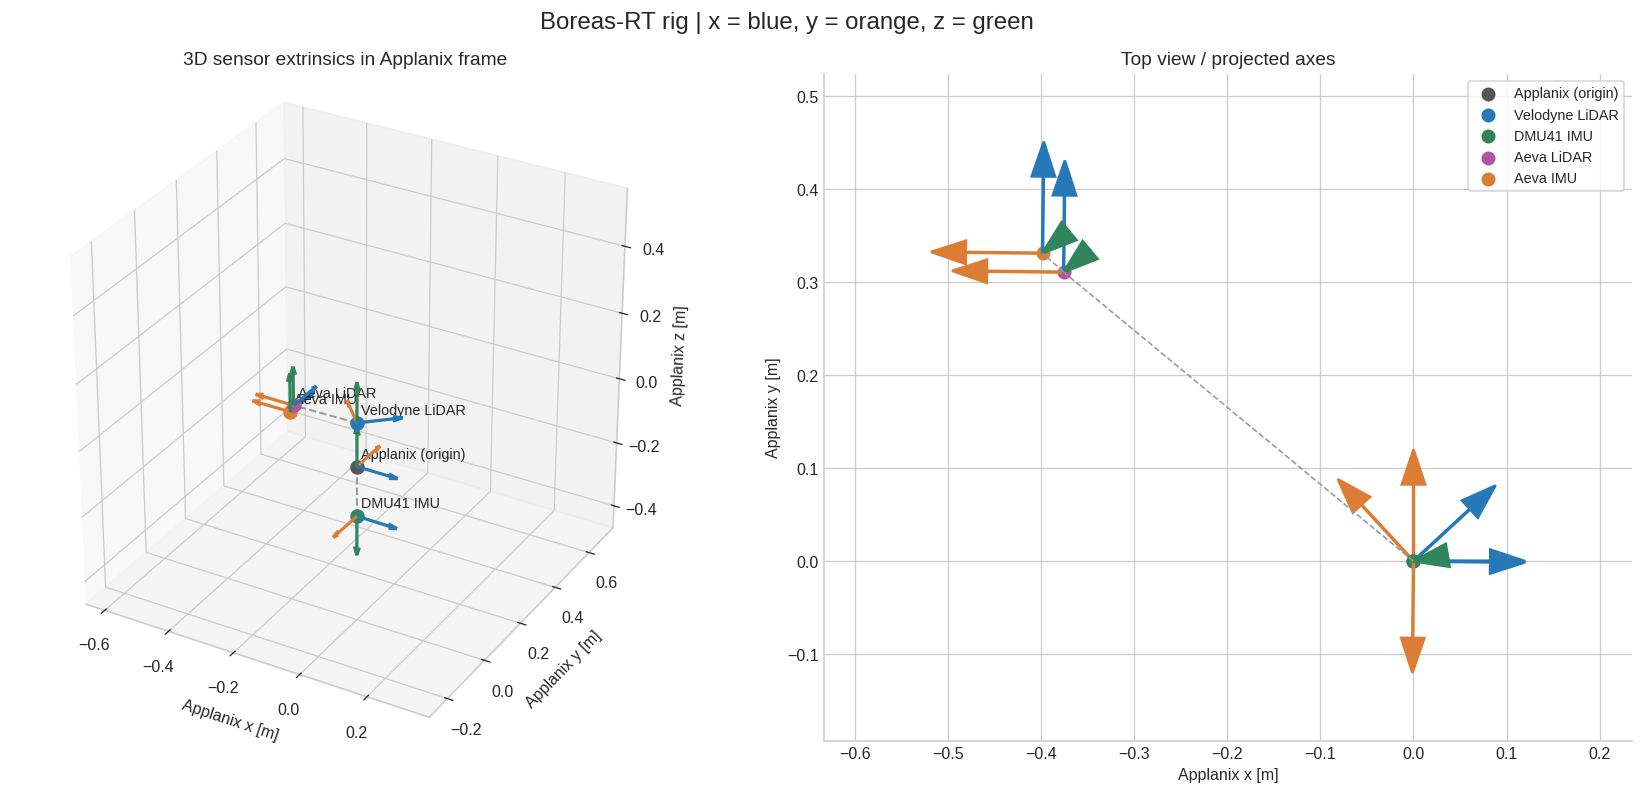

In [10]:
label_map = {"applanix": "Applanix (origin)", "velodyne": "Velodyne LiDAR", "aeva": "Aeva LiDAR",
             "dmu_infilled": "DMU41 IMU", "aeva_imu": "Aeva IMU"}
frame_colors = {"applanix": "#555555", **SENSOR_COLORS}
origin_points = np.array([T[:3, 3] for T in T_A_sensor.values()])
extent = max(np.ptp(origin_points, axis=0).max(), 0.25)
axis_length = max(0.12, 0.22 * extent)

fig = plt.figure(figsize=(15, 7))
ax = fig.add_subplot(121, projection="3d")
ax_xy = fig.add_subplot(122)
connections = [("applanix", "velodyne"), ("applanix", "dmu_infilled"),
               ("velodyne", "aeva"), ("aeva", "aeva_imu")]
for parent, child in connections:
    if parent in T_A_sensor and child in T_A_sensor:
        p0, p1 = T_A_sensor[parent][:3, 3], T_A_sensor[child][:3, 3]
        ax.plot(*np.column_stack((p0, p1)), color="#999999", lw=1.25, ls="--")
        ax_xy.plot([p0[0], p1[0]], [p0[1], p1[1]], color="#999999", lw=1.0, ls="--")
for name, T in T_A_sensor.items():
    p, R = T[:3, 3], T[:3, :3]
    color = frame_colors[name]
    ax.scatter(*p, s=65, c=color, depthshade=False)
    ax.text(*(p + [0.02 * extent, 0.02 * extent, 0.06 * extent]), label_map[name], fontsize=9)
    ax_xy.scatter(p[0], p[1], s=60, c=color, label=label_map[name])
    for k, axis_color in enumerate(AXIS_COLORS):
        direction = R[:, k] * axis_length
        ax.quiver(*p, *direction, color=axis_color, linewidth=2, arrow_length_ratio=0.22)
        ax_xy.arrow(p[0], p[1], direction[0], direction[1], color=axis_color,
                    head_width=0.025 * max(extent, 1.0), lw=1.6, length_includes_head=True)
ax.set(xlabel="Applanix x [m]", ylabel="Applanix y [m]", zlabel="Applanix z [m]",
       title="3D sensor extrinsics in Applanix frame")
equal_axes_3d(ax, np.vstack((origin_points, origin_points + axis_length)))
ax_xy.set(xlabel="Applanix x [m]", ylabel="Applanix y [m]", title="Top view / projected axes")
ax_xy.set_aspect("equal", adjustable="datalim")
ax_xy.legend(loc="best", fontsize=9)
fig.suptitle("Boreas-RT rig | x = blue, y = orange, z = green", fontsize=15)
finish_figure(fig, "sensor_calibrations_3d.png")

### 5.1. Pairwise IMU-to-LiDAR calibration matrices
For future extrinsic calibration, the most relevant transforms are `T_dmu_lidar`, `T_dmu_aeva`, `T_aeva_imu_lidar`, and `T_aeva_imu_aeva`. Each transforms a point from the named LiDAR frame into its target IMU frame. No manual adjustment of the provided calibration is performed.

In [11]:
pairwise = {}
for imu_key, imu_label in (("dmu_infilled", "dmu"), ("aeva_imu", "aeva_imu")):
    for lidar_key in LIDAR_NAMES:
        if imu_key in T_A_sensor and lidar_key in T_A_sensor:
            pairwise[f"T_{imu_label}_{lidar_key}"] = np.linalg.solve(T_A_sensor[imu_key], T_A_sensor[lidar_key])
for name, T in pairwise.items():
    print(f"{name}:\n{np.array2string(T, precision=5, suppress_small=True)}\n")

T_dmu_velodyne:
[[ 0.72826 -0.68529 -0.00142 -0.0004 ]
 [-0.6853  -0.72826  0.00026  0.00007]
 [-0.00121  0.00079 -1.      -0.28   ]
 [ 0.       0.       0.       1.     ]]

T_dmu_aeva:
[[ 0.00118 -0.99999 -0.00405 -0.37928]
 [-1.      -0.00119  0.00249 -0.30708]
 [-0.0025   0.00404 -0.99999 -0.06598]
 [ 0.       0.       0.       1.     ]]

T_aeva_imu_velodyne:
[[ 0.68616  0.72745  0.00224 -0.32617]
 [-0.72745  0.68616 -0.00263 -0.40311]
 [-0.00345  0.00017  0.99999  0.25025]
 [ 0.       0.       0.       1.     ]]

T_aeva_imu_aeva:
[[ 1.     0.     0.    -0.02 ]
 [-0.     1.    -0.    -0.023]
 [ 0.     0.     1.     0.037]
 [ 0.     0.     0.     1.   ]]



## 6. Reference trajectories for both LiDARs
Each `sequence.lidar_poses(source)` is a **sensor-specific** reference trajectory. Translational offsets between sensors mean their absolute ENU paths differ slightly. Plot both, including altitude and sampled heading, and retain the separate reference per LiDAR during odometry evaluation.

In [12]:
ground_truth = {}
for source in LIDAR_NAMES:
    folder = LIDAR_SOURCES[source][0]
    path = sequence.root / "applanix" / f"{folder}_poses.csv"
    if not path.is_file():
        print(f"Missing reference poses for {source}: {path}")
        continue
    trajectory = sequence.lidar_poses(source=source, time_start=TIME_START, time_end=TIME_END)
    if len(trajectory.timestamps_ns) < 2:
        print(f"Reference trajectory {source} has fewer than two poses in selected interval")
        continue
    ground_truth[source] = trajectory
    print(f"{LIDAR_LABELS[source]} ground truth: {len(trajectory.timestamps_ns):,} poses, "
          f"{relative_seconds(trajectory.timestamps_ns)[-1]:.1f} s")

Velodyne ground truth: 9,480 poses, 985.7 s
Aeva ground truth: 9,860 poses, 985.9 s


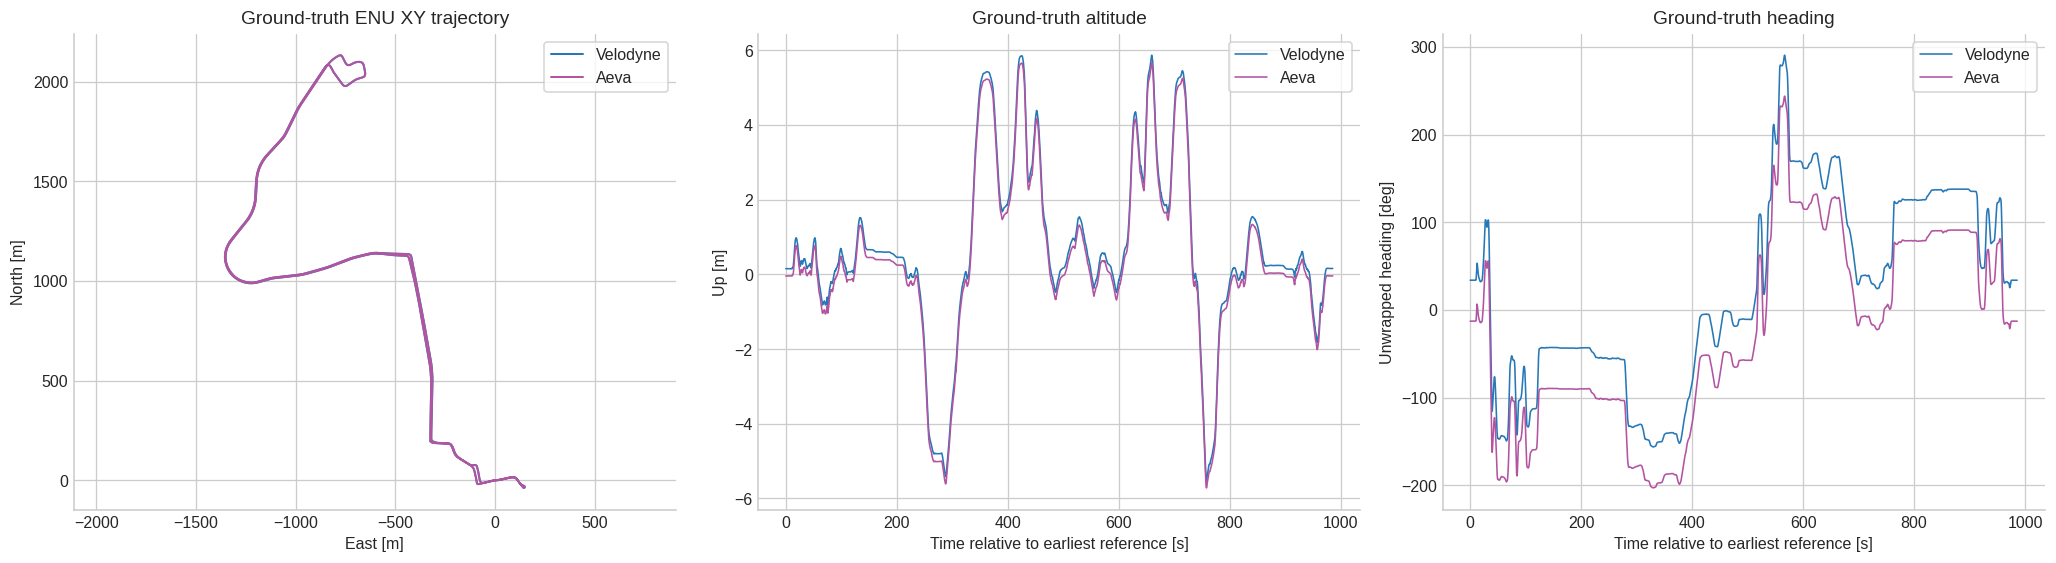

In [13]:
if ground_truth:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    gt_origin_ns = min(gt.timestamps_ns[0] for gt in ground_truth.values())
    for source, gt in ground_truth.items():
        idx = plotting_indices(len(gt.timestamps_ns))
        xyz = gt.poses_T_W_L[idx, :3, 3]
        t = relative_time(gt.timestamps_ns[idx], gt_origin_ns)
        col = SENSOR_COLORS[source]
        axes[0].plot(xyz[:, 0], xyz[:, 1], color=col, lw=1.25, label=LIDAR_LABELS[source])
        axes[1].plot(t, xyz[:, 2], color=col, lw=1.0, label=LIDAR_LABELS[source])
        if gt.rpy_rad is not None:
            axes[2].plot(t, np.unwrap(gt.rpy_rad[idx, 2]) * 180 / np.pi,
                         lw=1.0, color=col, label=LIDAR_LABELS[source])
    axes[0].set(xlabel="East [m]", ylabel="North [m]", title="Ground-truth ENU XY trajectory")
    axes[0].set_aspect("equal", adjustable="datalim")
    axes[1].set(xlabel="Time relative to earliest reference [s]", ylabel="Up [m]", title="Ground-truth altitude")
    axes[2].set(xlabel="Time relative to earliest reference [s]", ylabel="Unwrapped heading [deg]", title="Ground-truth heading")
    for ax in axes:
        ax.legend()
    finish_figure(fig, "both_lidar_ground_truth.png")

## 7. Load independent LiDAR odometry CSVs
The batch importer writes `lidar_odometry_velodyne.csv` and `lidar_odometry_aeva.csv` directly to the sequence root. These contain relative matrices, interval timestamps, fitness, inlier RMSE, and extraction metadata. The notebook **does not** run ICP itself.

To generate missing CSVs **outside** the notebook, for example from the repository root:

```bash
python src/boreas_dataset/import_lidar_odometry.py /mnt/d/Downloads/MobRobLab/BoreasDataset --sources velodyne aeva
```

Processing both full sequences can be computationally expensive. The importer has flags such as `--max-scans`, `--scan-step`, `--device`, and `--voxel-size-m`. These settings affect the independent odometry and should be retained in its metadata. Compare with reference only on the actual cached scan timestamps.

In [14]:
odometries = {}
odom_info = []
for source in LIDAR_NAMES:
    csv_path = sequence.root / f"lidar_odometry_{source}.csv"
    if not csv_path.is_file():
        print(f"Odometry missing for {LIDAR_LABELS[source]}: {csv_path.name} (skip independent odometry plots)")
        continue
    odom = load_lidar_data_csv(csv_path)
    validate_rigid_transform(odom.relative_poses_se3)
    if not odom.metadata.get("independent_odometry", False):
        raise ValueError(f"{csv_path} is not marked independent odometry: refusing to label it scan registration")
    odometries[source] = odom
    odom_info.append({"sensor": LIDAR_LABELS[source], "intervals": len(odom.relative_poses_se3),
                      "median fitness": float(np.median(odom.fitness)),
                      "median ICP RMSE [m]": float(np.median(odom.inlier_rmse)),
                      "registration": odom.metadata.get("registration", "unspecified"),
                      "scan step": odom.metadata.get("scan_step"),
                      "deskewed": odom.metadata.get("deskewed"),
                      "uses GT": odom.metadata.get("uses_ground_truth")})
if odom_info:
    display(pd.DataFrame(odom_info).set_index("sensor"))

,intervals,median fitness,median ICP RMSE [m],registration,scan step,deskewed,uses GT
sensor,,,,,,,
Velodyne,9479,0.984537,0.163558,open3d_tensor_multiscale_point_to_plane_icp,1,False,False
Aeva,9859,0.980036,0.187018,open3d_tensor_multiscale_point_to_plane_icp,1,False,False


## 8. Integrate the relative scan odometry and match the reference

The odometry cache stores `scan_timestamps_s` (one more timestamp than transforms). It may also contain integer `scan_timestamps_ns` in `metadata` from the importer, preferred to avoid loss of epoch precision. The loader matches reference poses at **those exact scan times**, with controlled interpolation. It retains the **longest contiguous available block** inside the reference coverage when time bounds differ. No GT is used inside ICP or the integration loop.

For each LiDAR:

\[
\hat T_{L_0L_k} = \prod_{i=1}^k \hat T_{L_{i-1}L_i}, \qquad
\hat T_{WL_k} = T^{\mathrm{GT}}_{WL_0}\hat T_{L_0L_k}.
\]

We report a **first-pose-anchored** path error plus per-step relative transformation error, not an optimally aligned ATE benchmark. Error comparisons use the reference trajectory of the *same* LiDAR.

In [15]:
def odometry_scan_timestamps_ns(odom):
    """Use exact importer metadata when present; otherwise reconstruct from CSV seconds."""
    raw = odom.metadata.get("scan_timestamps_ns")
    if isinstance(raw, list) and len(raw) == len(odom.scan_timestamps_s):
        ns = np.asarray(raw, dtype=np.int64)
        if np.any(np.diff(ns) <= 0):
            raise ValueError("Invalid scan_timestamps_ns metadata")
        if np.max(np.abs(ns.astype(np.float64) * 1e-9 - odom.scan_timestamps_s)) > 1e-3:
            raise ValueError("Nanosecond metadata disagrees with saved CSV seconds")
        return ns
    # CSV UTC float seconds lose a few hundred ns of resolution at modern epochs;
    # pose matching tolerates this, and no high-frequency differencing uses them.
    return np.asarray([timestamps_to_ns([str(float(t))], "s")[0] for t in odom.scan_timestamps_s], dtype=np.int64)


def integrated_poses(relative_T):
    """T_previous_current increments -> T_first_current for all scans."""
    inc = np.asarray(relative_T, dtype=float)
    validate_rigid_transform(inc)
    out = np.repeat(np.eye(4)[None, :, :], len(inc) + 1, axis=0)
    for i in range(len(inc)):
        out[i + 1] = out[i] @ inc[i]
    return out


def align_and_evaluate_odometry(odom, reference):
    ns = odometry_scan_timestamps_ns(odom)
    valid = np.flatnonzero((ns >= reference.timestamps_ns[0]) & (ns <= reference.timestamps_ns[-1]))
    if valid.size < 2:
        raise ValueError("No reference-overlapping odometry interval")
    begin, end = int(valid[0]), int(valid[-1])
    if np.any(np.diff(valid) != 1):
        raise ValueError("Reference-overlapping odometry scans are not contiguous")
    selected_ns = ns[begin:end + 1]
    inc = odom.relative_poses_se3[begin:end]
    gt = reference.match(selected_ns, tolerance_s=POSE_MATCH_TOLERANCE_S,
                         interpolate=True, max_gap_s=POSE_INTERPOLATION_MAX_GAP_S)
    local = integrated_poses(inc)
    estimate = gt[0] @ local   # first-pose anchor, NOT a multi-pose rigid alignment
    error = np.linalg.solve(gt, estimate)
    position_error = np.linalg.norm(estimate[:, :3, 3] - gt[:, :3, 3], axis=1)
    orientation_error_deg = np.rad2deg(Rotation.from_matrix(error[:, :3, :3]).magnitude())
    gt_relative = np.linalg.solve(gt[:-1], gt[1:])
    step_error = np.linalg.solve(gt_relative, inc)
    step_translation_error_m = np.linalg.norm(step_error[:, :3, 3], axis=1)
    step_rotation_error_deg = np.rad2deg(Rotation.from_matrix(step_error[:, :3, :3]).magnitude())
    gt_step_translation, gt_step_angle = motion_magnitudes(gt_relative)
    odom_step_translation, odom_step_angle = motion_magnitudes(inc)
    return {"ns": selected_ns, "relative": inc, "gt_relative": gt_relative,
            "gt": gt, "estimated": estimate, "local": local,
            "position_error_m": position_error, "orientation_error_deg": orientation_error_deg,
            "step_translation_error_m": step_translation_error_m,
            "step_rotation_error_deg": step_rotation_error_deg,
            "gt_step_translation_m": gt_step_translation,
            "odom_step_translation_m": odom_step_translation,
            "gt_step_angle_deg": np.rad2deg(gt_step_angle),
            "odom_step_angle_deg": np.rad2deg(odom_step_angle),
            "fitness": odom.fitness[begin:end], "inlier_rmse": odom.inlier_rmse[begin:end],
            "first_odom_scan_index": begin, "last_odom_scan_index": end}

# Unit sanity check for integration direction: applying two pure translations
# in the +x direction must place the third scan at x=2 in its first-frame path.
translation_test = np.repeat(np.eye(4)[None], 2, axis=0)
translation_test[:, 0, 3] = 1.0
assert np.allclose(integrated_poses(translation_test)[:, 0, 3], [0.0, 1.0, 2.0])

comparisons = {}
for source, odom in odometries.items():
    if source not in ground_truth:
        print(f"No {source} ground truth: cannot evaluate odometry")
        continue
    try:
        comparison = align_and_evaluate_odometry(odom, ground_truth[source])
    except (ValueError, IndexError) as exc:
        print(f"Could not match {LIDAR_LABELS[source]} odometry to ground truth: {exc}")
        continue
    comparisons[source] = comparison
    print(f"{LIDAR_LABELS[source]}: {len(comparison['relative']):,} matched intervals, "
          f"odom scan indices {comparison['first_odom_scan_index']}–{comparison['last_odom_scan_index']}; "
          f"elapsed {relative_seconds(comparison['ns'])[-1]:.1f} s")

Velodyne: 9,479 matched intervals, odom scan indices 0–9479; elapsed 985.7 s
Aeva: 9,859 matched intervals, odom scan indices 0–9859; elapsed 985.9 s


## 9. Odometry figures, separately for each LiDAR
The next cells create the same three groups of plots for Velodyne and Aeva. These use **actual scan-matching results** from the cache and the same-sensor Applanix reference.

- **Paths:** integrated versus reference in ENU XY and 3D, with a common initial pose.
- **Relative odometry:** translation components and rotation-vector components, plus step magnitudes. Rotations are represented as `Rotation.as_rotvec()` for each *single relative increment*, not Euler-angle differences.
- **Error and ICP quality:** accumulated translation and rotation drift, per-interval relative pose error, ICP fitness and inlier RMSE.

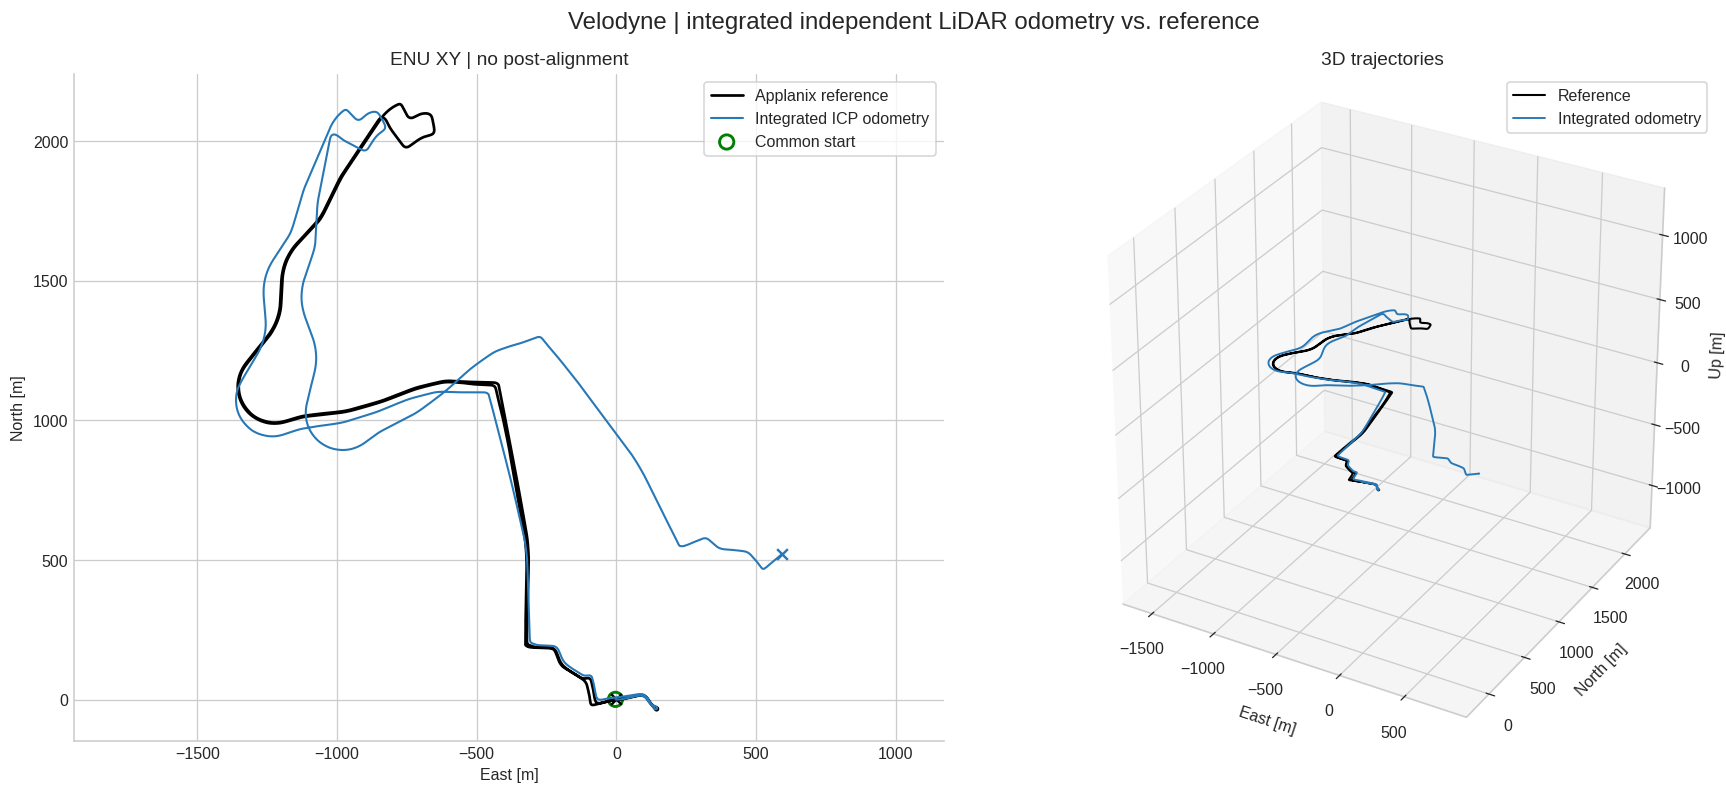

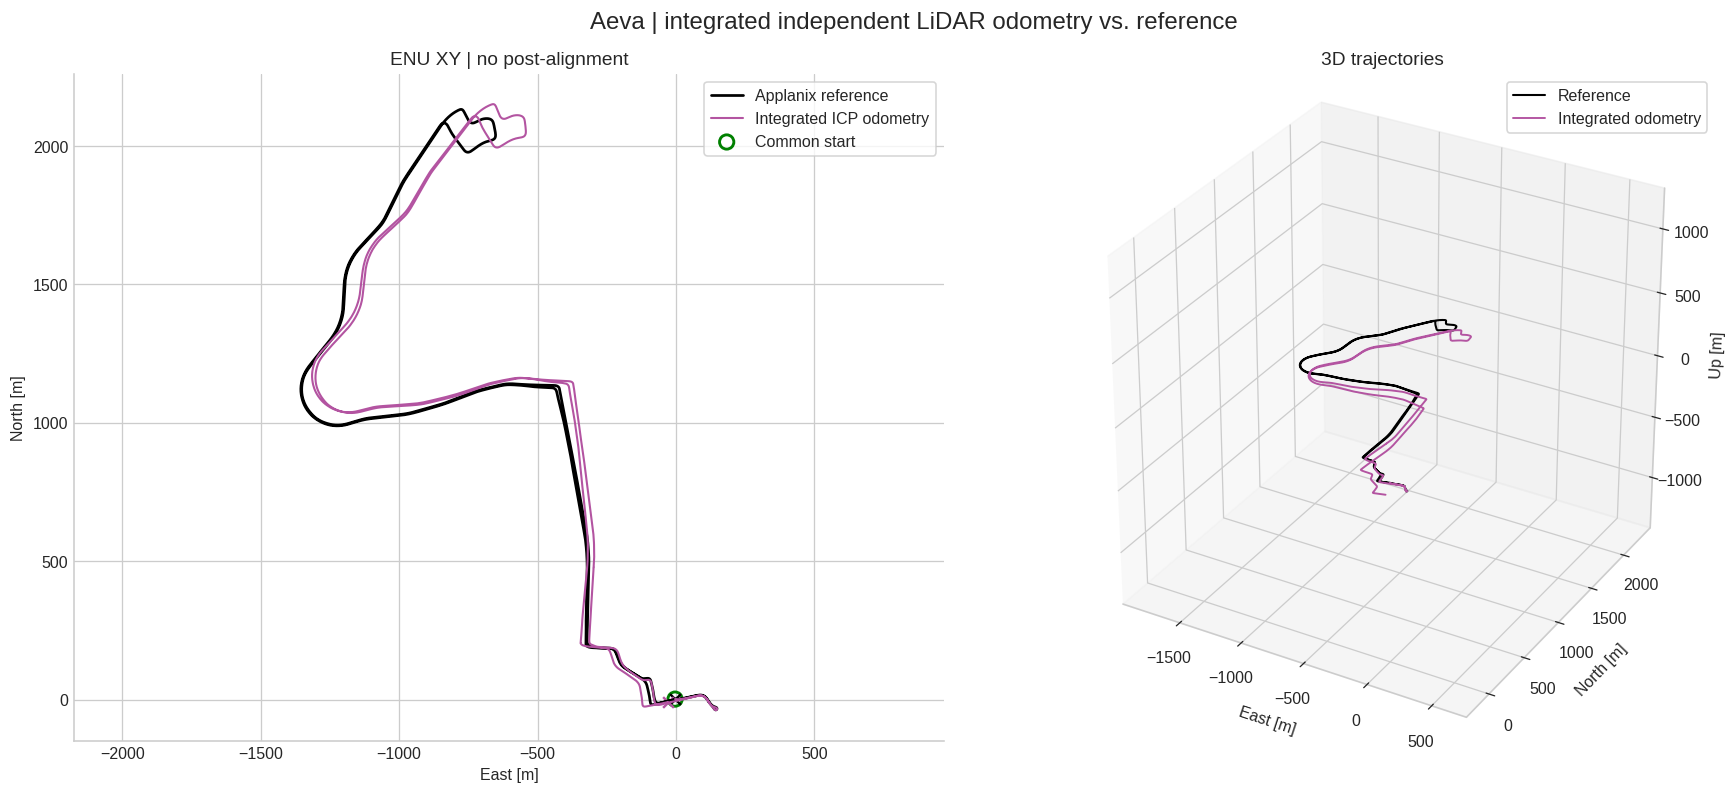

In [16]:
for source, result in comparisons.items():
    est_xyz = result["estimated"][:, :3, 3]
    gt_xyz = result["gt"][:, :3, 3]
    idx = plotting_indices(len(est_xyz))
    color = SENSOR_COLORS[source]
    fig = plt.figure(figsize=(16, 7))
    ax_xy = fig.add_subplot(121)
    ax_3d = fig.add_subplot(122, projection="3d")
    ax_xy.plot(gt_xyz[idx, 0], gt_xyz[idx, 1], color="black", lw=1.7, label="Applanix reference")
    ax_xy.plot(est_xyz[idx, 0], est_xyz[idx, 1], color=color, lw=1.3, label="Integrated ICP odometry")
    ax_xy.scatter(gt_xyz[0, 0], gt_xyz[0, 1], s=80, marker="o", facecolors="none", edgecolors="green", lw=1.8,
                  label="Common start")
    ax_xy.scatter(gt_xyz[-1, 0], gt_xyz[-1, 1], s=45, color="black", marker="x")
    ax_xy.scatter(est_xyz[-1, 0], est_xyz[-1, 1], s=45, color=color, marker="x")
    ax_xy.set(xlabel="East [m]", ylabel="North [m]", title="ENU XY | no post-alignment")
    ax_xy.set_aspect("equal", adjustable="datalim")
    ax_xy.legend(loc="best")
    ax_3d.plot(*gt_xyz[idx].T, color="black", lw=1.3, label="Reference")
    ax_3d.plot(*est_xyz[idx].T, color=color, lw=1.2, label="Integrated odometry")
    ax_3d.set(xlabel="East [m]", ylabel="North [m]", zlabel="Up [m]", title="3D trajectories")
    equal_axes_3d(ax_3d, np.vstack((gt_xyz[idx], est_xyz[idx])))
    ax_3d.legend(loc="best")
    fig.suptitle(f"{LIDAR_LABELS[source]} | integrated independent LiDAR odometry vs. reference", fontsize=15)
    finish_figure(fig, f"{source}_trajectory_vs_gt.png")

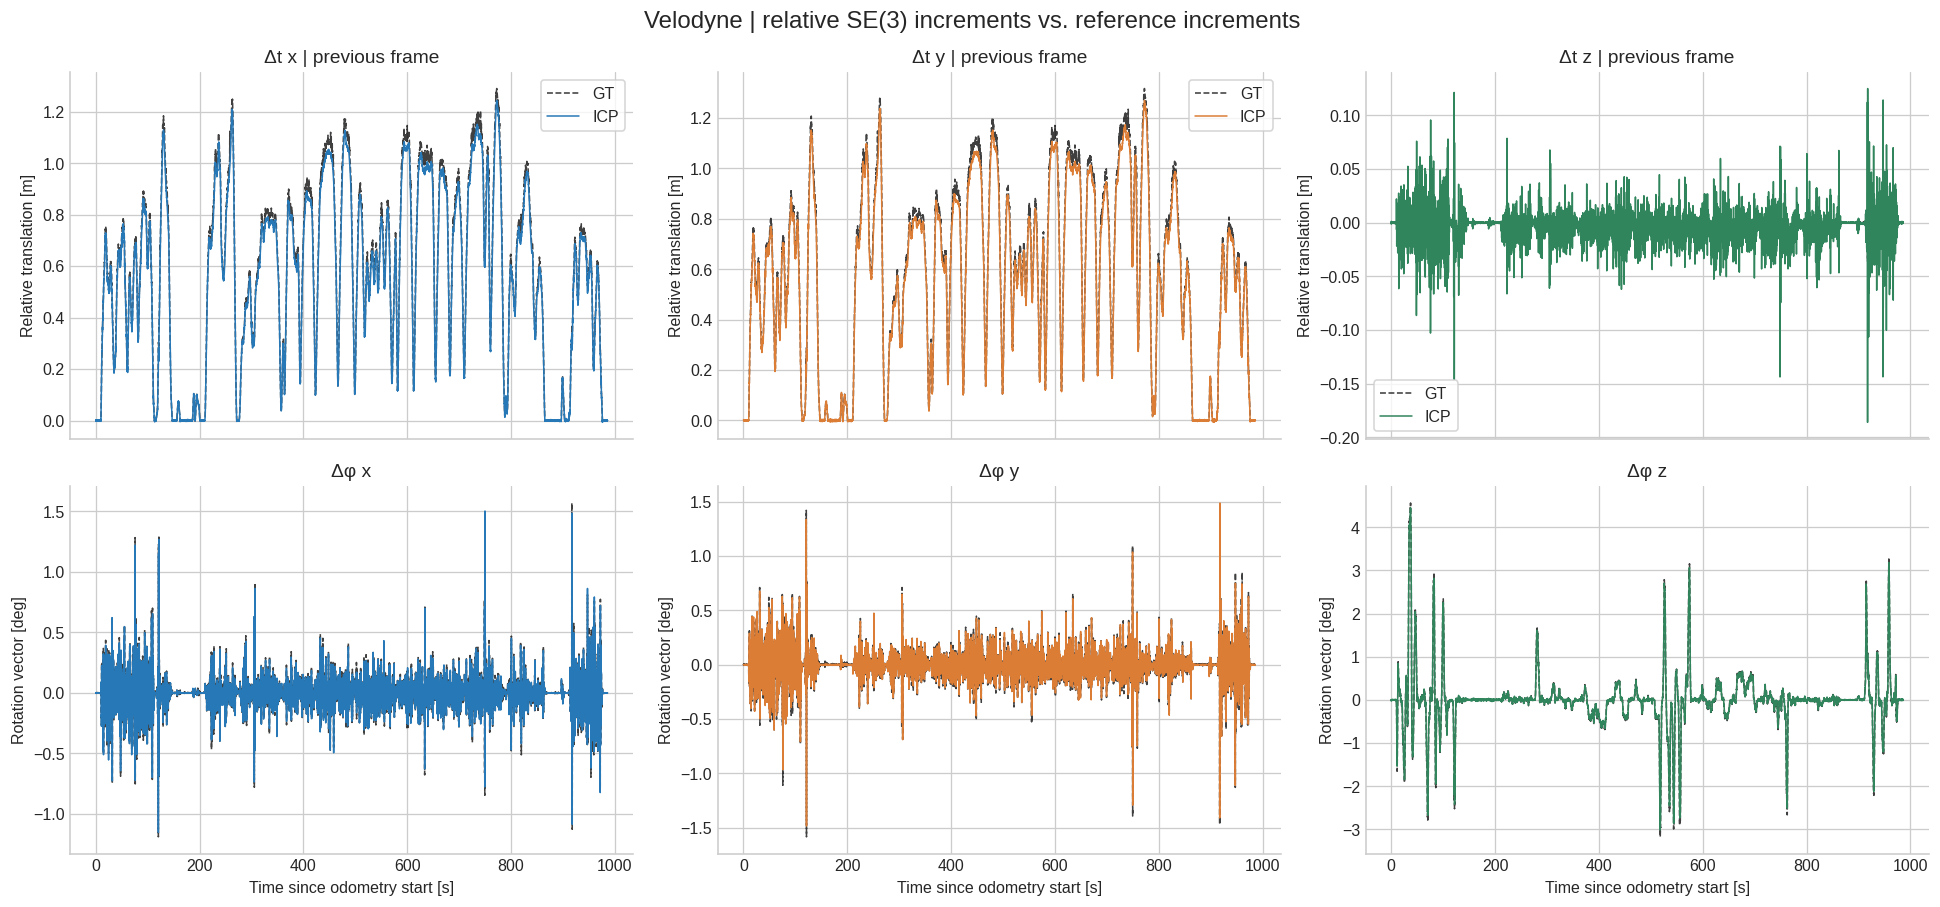

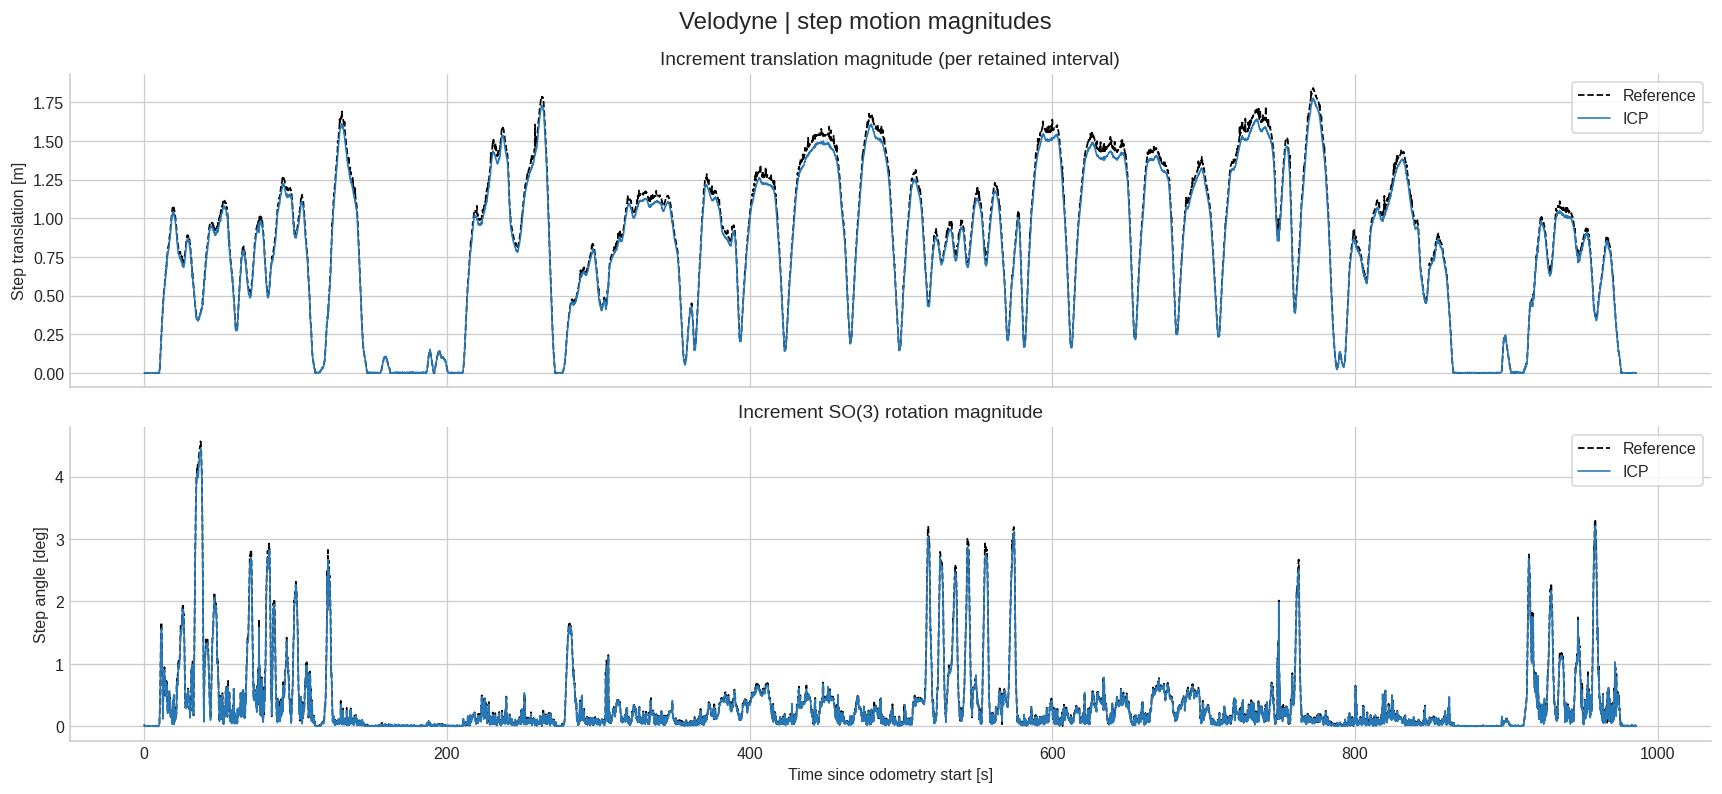

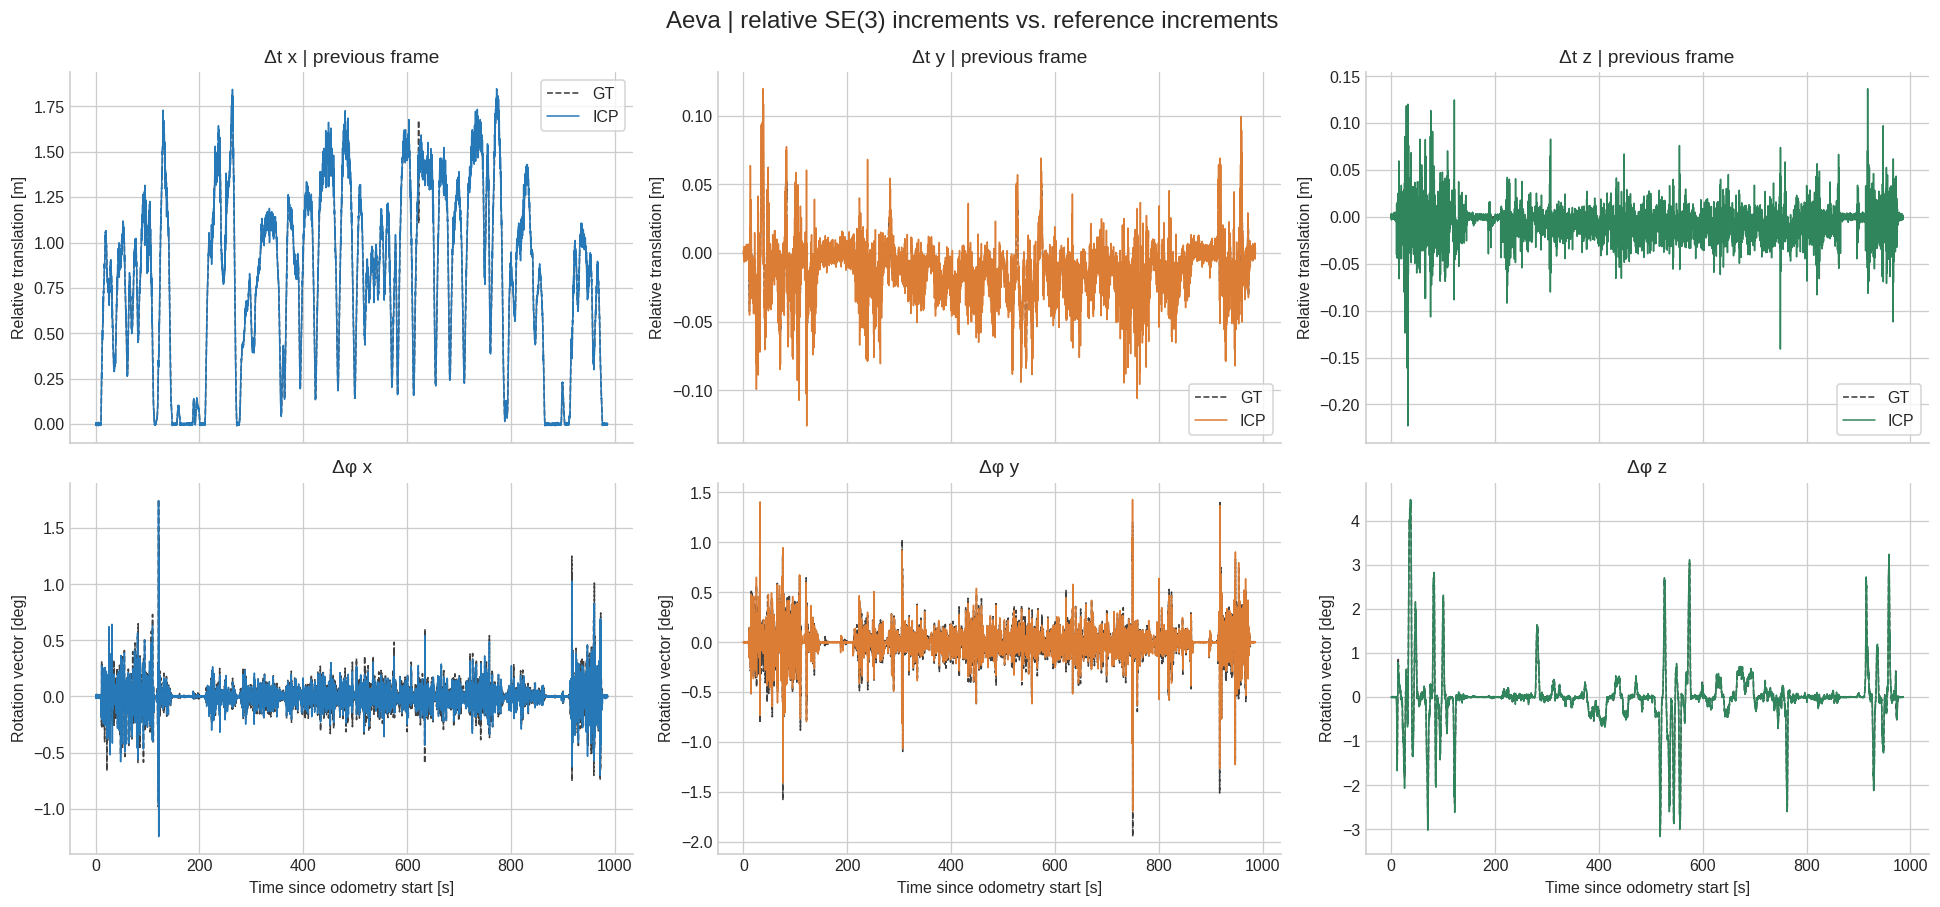

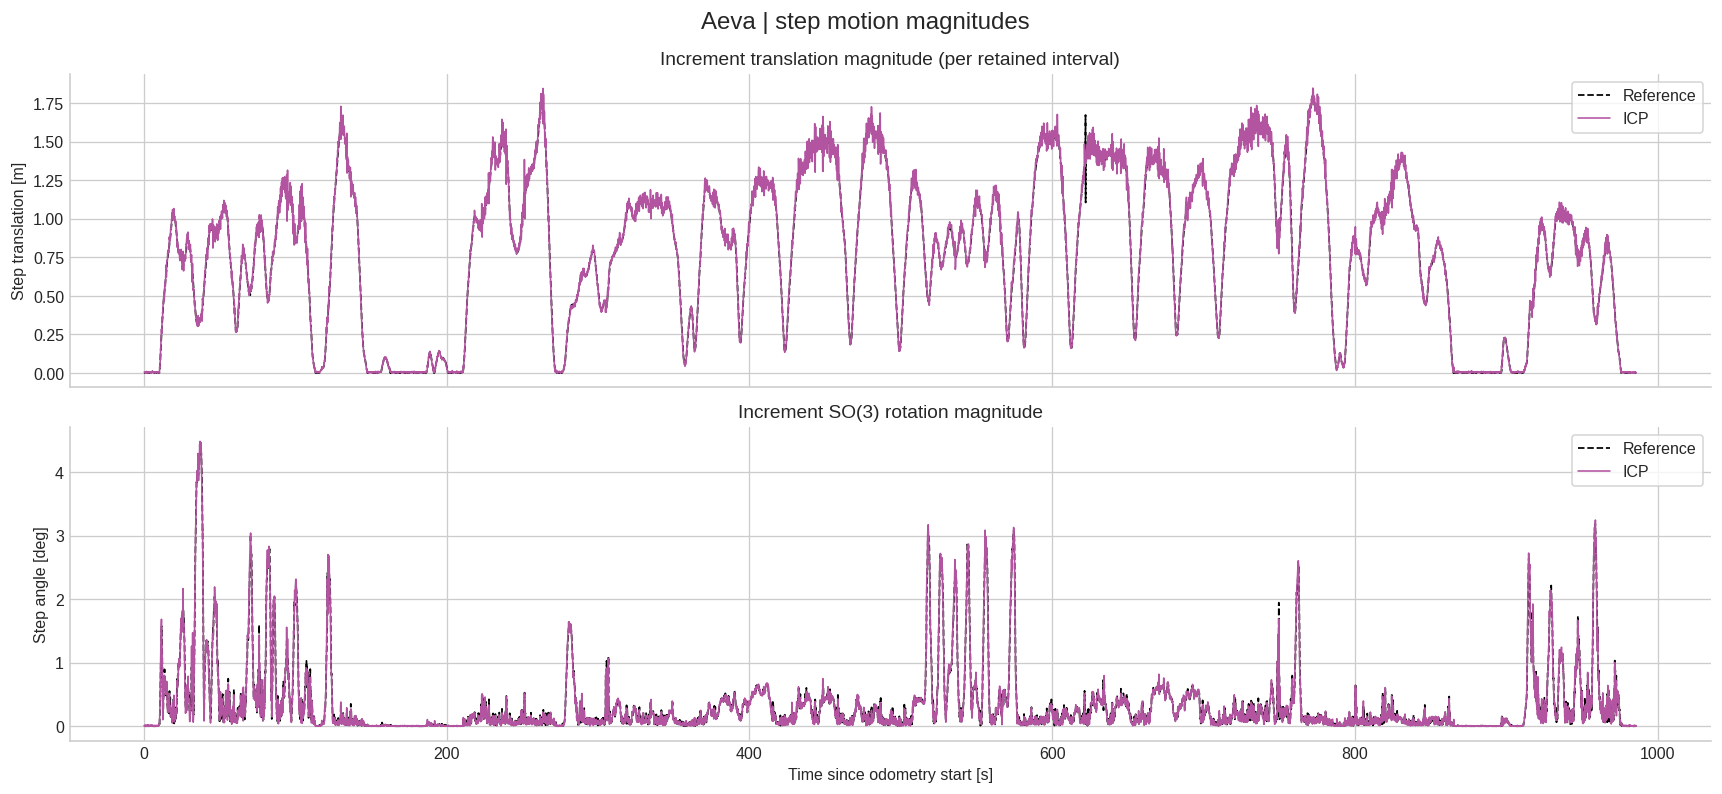

In [17]:
for source, result in comparisons.items():
    inc = result["relative"]
    gt_inc = result["gt_relative"]
    t = relative_time(result["ns"][1:], result["ns"][0])
    idx = plotting_indices(len(inc))
    est_t = inc[:, :3, 3]
    ref_t = gt_inc[:, :3, 3]
    est_w = np.rad2deg(Rotation.from_matrix(inc[:, :3, :3]).as_rotvec())
    ref_w = np.rad2deg(Rotation.from_matrix(gt_inc[:, :3, :3]).as_rotvec())
    fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
    for k, axis_name in enumerate("xyz"):
        c = AXIS_COLORS[k]
        axes[0, k].plot(t[idx], ref_t[idx, k], "--", lw=1.0, color="black", alpha=0.75, label="GT")
        axes[0, k].plot(t[idx], est_t[idx, k], lw=0.95, color=c, label="ICP")
        axes[0, k].set(ylabel="Relative translation [m]", title=f"Δt {axis_name} | previous frame")
        axes[1, k].plot(t[idx], ref_w[idx, k], "--", lw=1.0, color="black", alpha=0.75, label="GT")
        axes[1, k].plot(t[idx], est_w[idx, k], lw=0.95, color=c, label="ICP")
        axes[1, k].set(xlabel="Time since odometry start [s]", ylabel="Rotation vector [deg]", title=f"Δφ {axis_name}")
        axes[0, k].legend()
    fig.suptitle(f"{LIDAR_LABELS[source]} | relative SE(3) increments vs. reference increments", fontsize=15)
    finish_figure(fig, f"{source}_relative_components.png")

    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    axes[0].plot(t[idx], result["gt_step_translation_m"][idx], "--", color="black", lw=1.1, label="Reference")
    axes[0].plot(t[idx], result["odom_step_translation_m"][idx], color=SENSOR_COLORS[source], lw=1.0, label="ICP")
    axes[0].set(ylabel="Step translation [m]", title="Increment translation magnitude (per retained interval)")
    axes[1].plot(t[idx], result["gt_step_angle_deg"][idx], "--", color="black", lw=1.1, label="Reference")
    axes[1].plot(t[idx], result["odom_step_angle_deg"][idx], color=SENSOR_COLORS[source], lw=1.0, label="ICP")
    axes[1].set(xlabel="Time since odometry start [s]", ylabel="Step angle [deg]", title="Increment SO(3) rotation magnitude")
    for ax in axes:
        ax.legend()
    fig.suptitle(f"{LIDAR_LABELS[source]} | step motion magnitudes", fontsize=15)
    finish_figure(fig, f"{source}_relative_magnitudes.png")

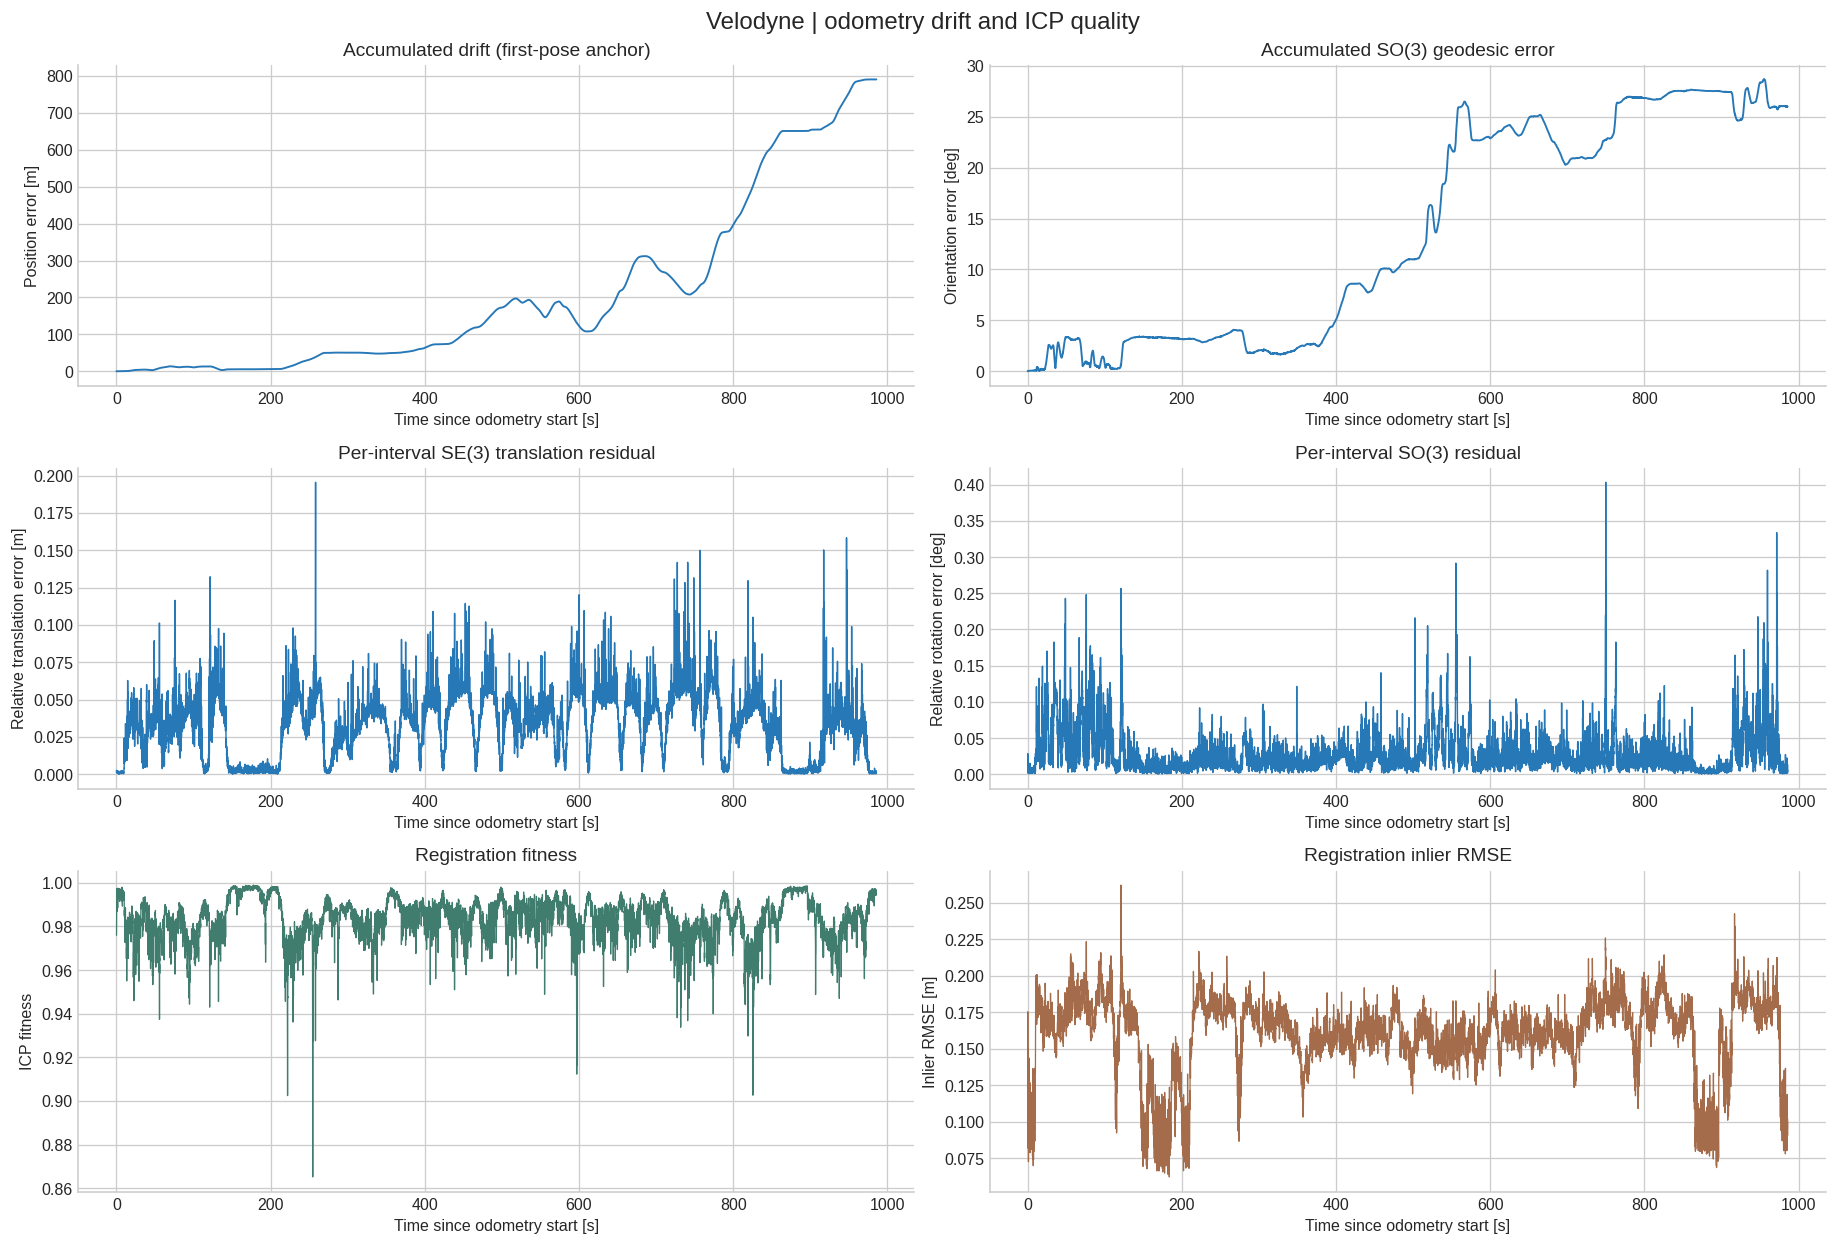

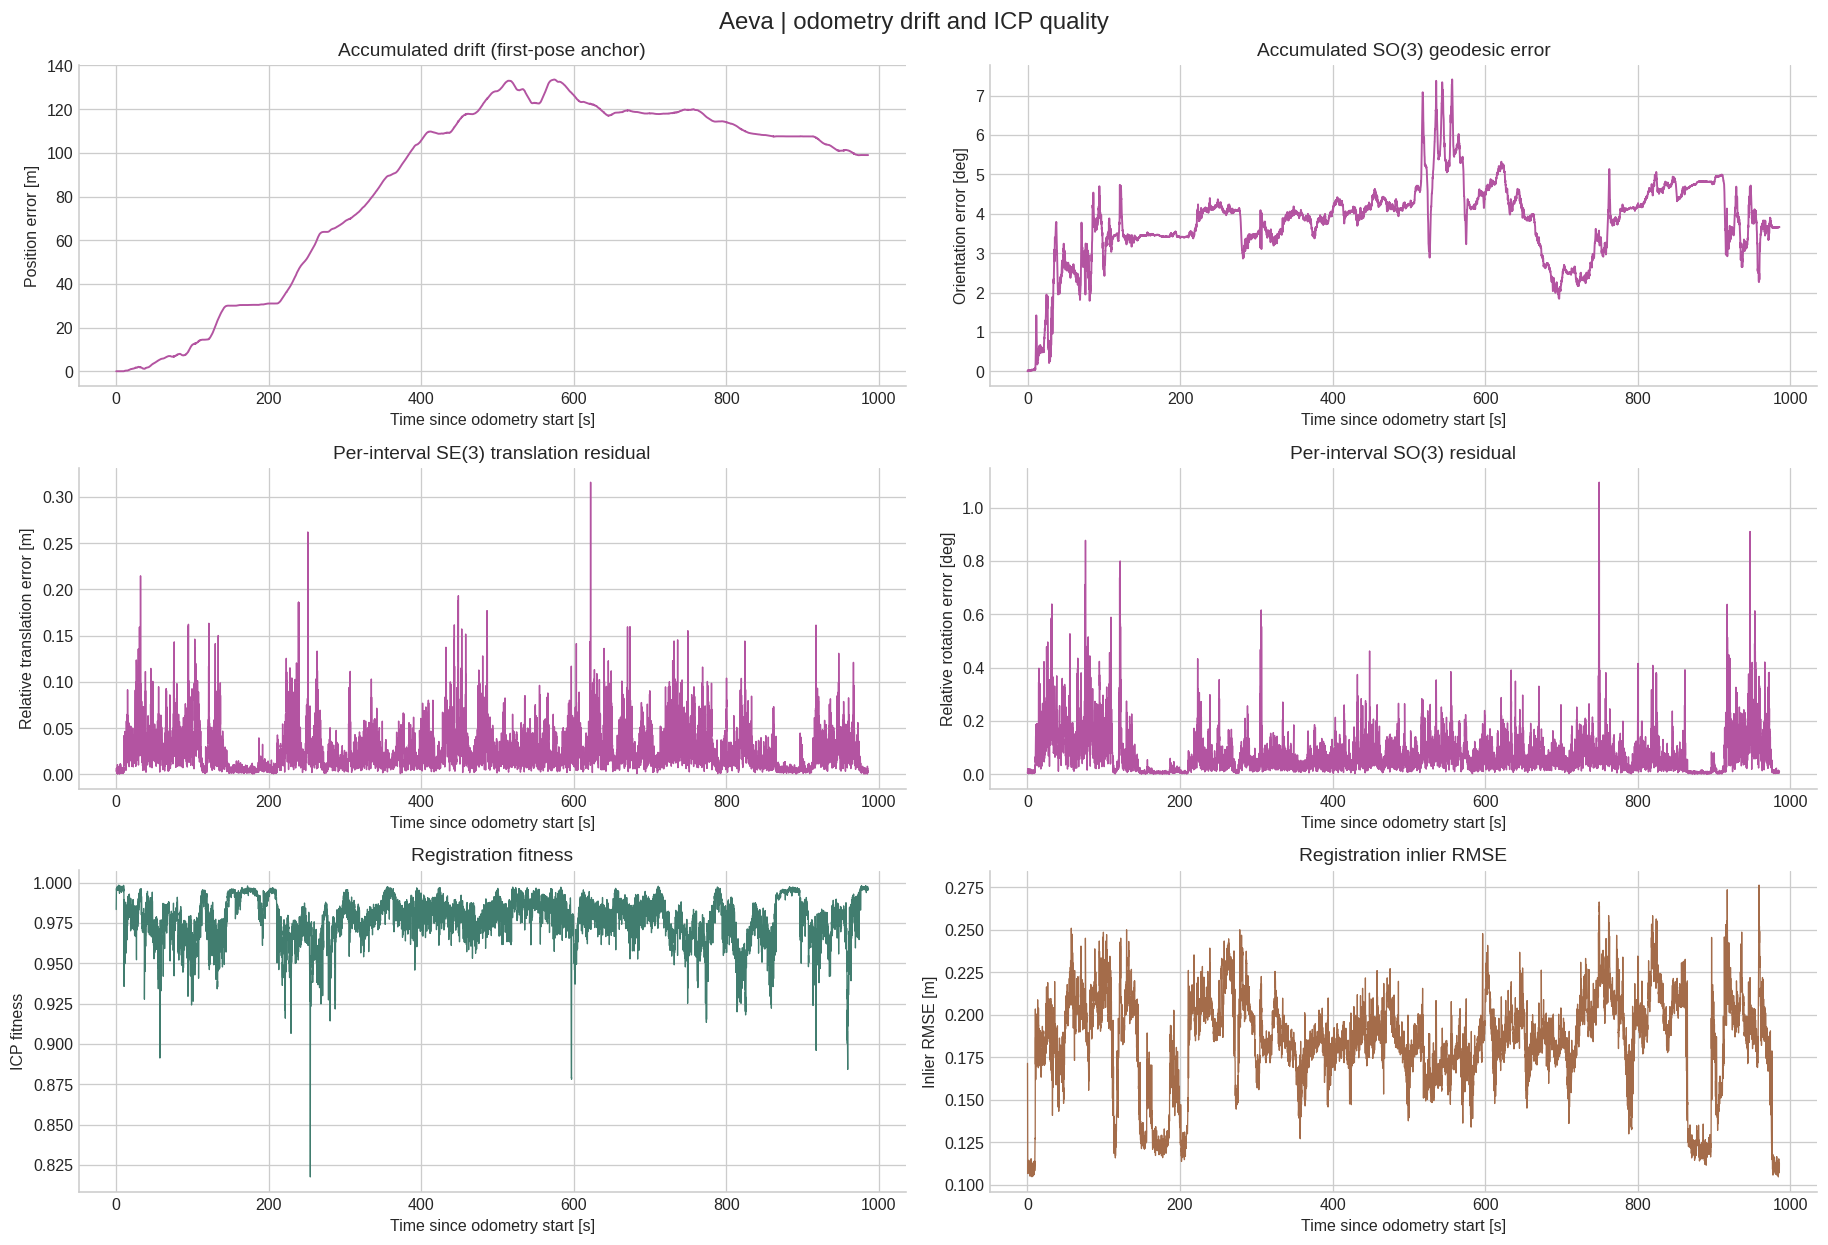

In [18]:
for source, result in comparisons.items():
    t_pose = relative_time(result["ns"], result["ns"][0])
    t_step = t_pose[1:]
    idx_pose = plotting_indices(len(t_pose))
    idx_step = plotting_indices(len(t_step))
    color = SENSOR_COLORS[source]
    fig, axes = plt.subplots(3, 2, figsize=(16, 11))
    axes[0, 0].plot(t_pose[idx_pose], result["position_error_m"][idx_pose], color=color, lw=1.2)
    axes[0, 1].plot(t_pose[idx_pose], result["orientation_error_deg"][idx_pose], color=color, lw=1.2)
    axes[1, 0].plot(t_step[idx_step], result["step_translation_error_m"][idx_step], color=color, lw=0.9)
    axes[1, 1].plot(t_step[idx_step], result["step_rotation_error_deg"][idx_step], color=color, lw=0.9)
    axes[2, 0].plot(t_step[idx_step], result["fitness"][idx_step], color="#417d6f", lw=0.8)
    axes[2, 1].plot(t_step[idx_step], result["inlier_rmse"][idx_step], color="#a46c4a", lw=0.8)
    axes[0, 0].set(ylabel="Position error [m]", title="Accumulated drift (first-pose anchor)")
    axes[0, 1].set(ylabel="Orientation error [deg]", title="Accumulated SO(3) geodesic error")
    axes[1, 0].set(ylabel="Relative translation error [m]", title="Per-interval SE(3) translation residual")
    axes[1, 1].set(ylabel="Relative rotation error [deg]", title="Per-interval SO(3) residual")
    axes[2, 0].set(ylabel="ICP fitness", title="Registration fitness")
    axes[2, 1].set(ylabel="Inlier RMSE [m]", title="Registration inlier RMSE")
    for ax in axes.flat:
        ax.set_xlabel("Time since odometry start [s]")
    fig.suptitle(f"{LIDAR_LABELS[source]} | odometry drift and ICP quality", fontsize=15)
    finish_figure(fig, f"{source}_error_and_quality.png")

## 10. Side-by-side drift summary and comparison
All errors are **first-pose-anchored** and calculated against each sensor's own GT trajectory, at its actual odometry timestamps. Absolute path quality depends on sequence length, registration settings, local map configuration, scan rates, lack of deskew, and available geometry. We report **duration and path length** so truncated caches are not misinterpreted as full-run results. Per-interval step errors are directly comparable only with their interval durations taken into account.

In [19]:
metric_rows = []
for source, result in comparisons.items():
    gt_xyz = result["gt"][:, :3, 3]
    ref_dist = float(np.linalg.norm(np.diff(gt_xyz, axis=0), axis=1).sum())
    drift = result["position_error_m"]
    angle = result["orientation_error_deg"]
    metric_rows.append({"lidar": LIDAR_LABELS[source],
                        "intervals": len(result["relative"]),
                        "duration [s]": relative_seconds(result["ns"])[-1],
                        "reference distance [m]": ref_dist,
                        "final pos error [m]": drift[-1],
                        "position RMSE [m]": float(np.sqrt(np.mean(drift**2))),
                        "final rot error [deg]": angle[-1],
                        "rotation RMSE [deg]": float(np.sqrt(np.mean(angle**2))),
                        "relative translation RMSE [m]": float(np.sqrt(np.mean(result["step_translation_error_m"]**2))),
                        "relative rotation RMSE [deg]": float(np.sqrt(np.mean(result["step_rotation_error_deg"]**2))),
                        "final drift [% dist]": 100 * drift[-1] / ref_dist if ref_dist > 0 else np.nan})
if metric_rows:
    display(pd.DataFrame(metric_rows).set_index("lidar").round(4))
else:
    print("No evaluable independent odometry CSVs found. Raw sensors, calibrations and reference plots remain usable.")

,intervals,duration [s],reference distance [m],final pos error [m],position RMSE [m],final rot error [deg],rotation RMSE [deg],relative translation RMSE [m],relative rotation RMSE [deg],final drift [% dist]
lidar,,,,,,,,,,
Velodyne,9479,985.7437,7932.7451,790.7614,313.3217,26.0021,17.4041,0.0397,0.0401,9.9683
Aeva,9859,985.9000,7933.1127,98.9646,95.6313,3.6630,3.9132,0.0344,0.1092,1.2475


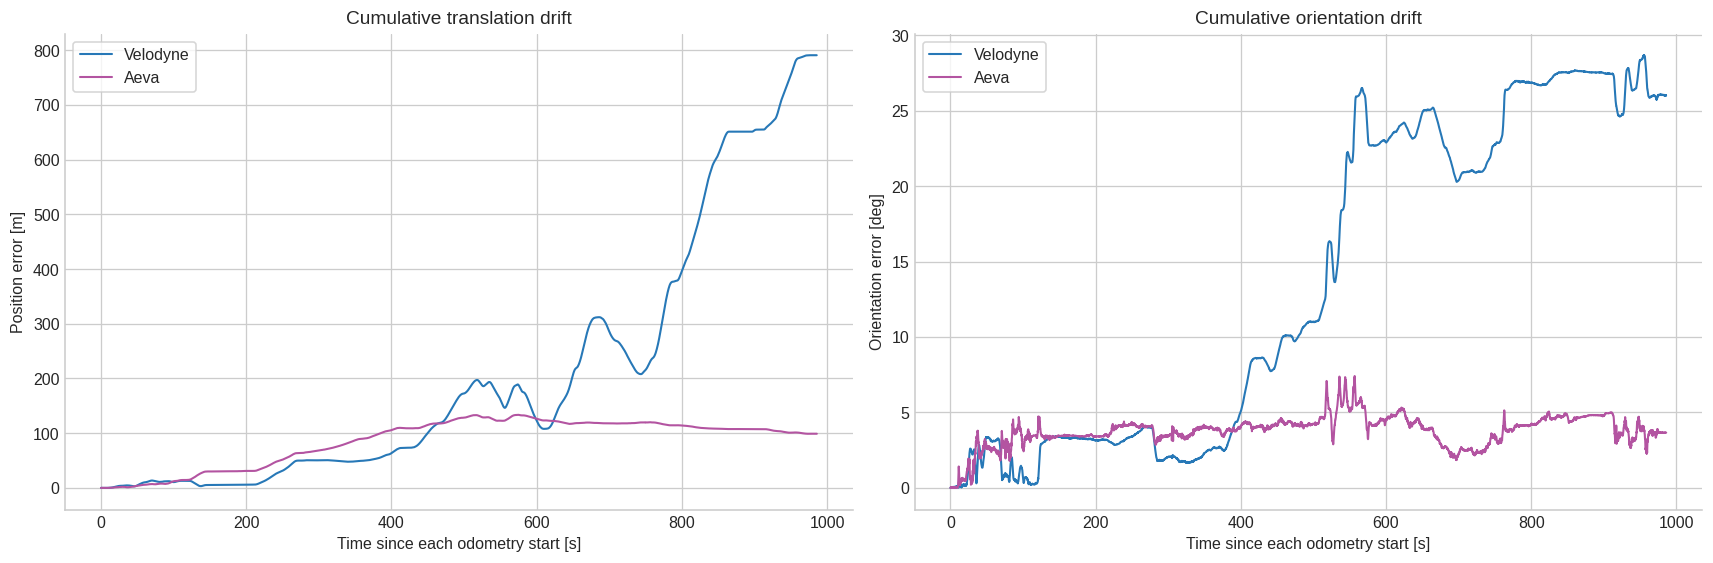

In [20]:
if comparisons:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for source, result in comparisons.items():
        t = relative_time(result["ns"], result["ns"][0])
        idx = plotting_indices(len(t))
        axes[0].plot(t[idx], result["position_error_m"][idx], color=SENSOR_COLORS[source],
                     lw=1.3, label=LIDAR_LABELS[source])
        axes[1].plot(t[idx], result["orientation_error_deg"][idx], color=SENSOR_COLORS[source],
                     lw=1.3, label=LIDAR_LABELS[source])
    axes[0].set(title="Cumulative translation drift", xlabel="Time since each odometry start [s]", ylabel="Position error [m]")
    axes[1].set(title="Cumulative orientation drift", xlabel="Time since each odometry start [s]", ylabel="Orientation error [deg]")
    for ax in axes:
        ax.legend()
    finish_figure(fig, "both_lidar_drift_comparison.png")

## 11. Time coverage across the four sensors
A simple timing overview shows which measurements overlap. It is often useful when preparing multi-sensor calibration windows. Dots shown on the plot are **display-only** downsampled timestamps; no streams are resampled.

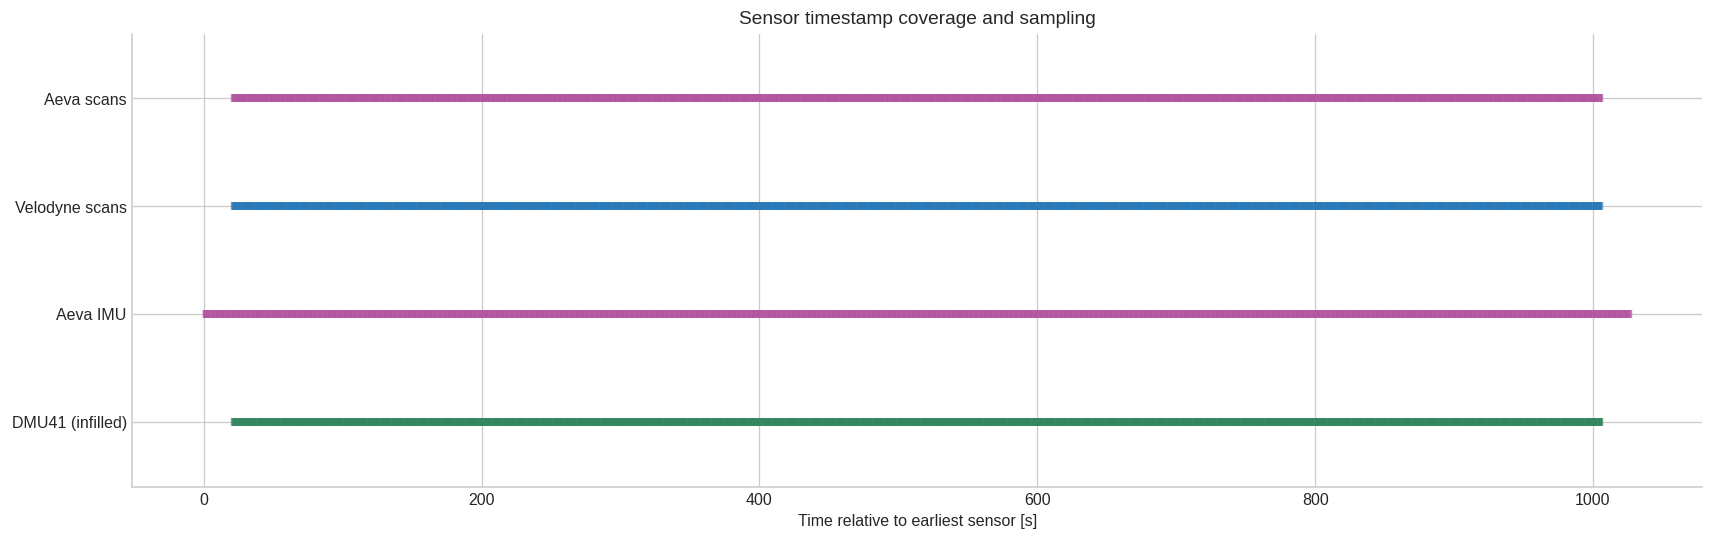

In [21]:
coverage_items = []
for source, imu in imus.items():
    coverage_items.append((IMU_LABELS[source], imu.timestamps_ns, SENSOR_COLORS[source]))
for source, scans in lidar_scans.items():
    coverage_items.append((f"{LIDAR_LABELS[source]} scans", np.array([scan.timestamp_ns for scan in scans], dtype=np.int64), SENSOR_COLORS[source]))
if coverage_items:
    common_origin_ns = min(arr[0] for _, arr, _ in coverage_items if len(arr))
    fig, ax = plt.subplots(figsize=(15, 4.8))
    for row_number, (name, ns, color) in enumerate(coverage_items):
        idx = plotting_indices(len(ns), 2000)
        ax.scatter(relative_time(ns[idx], common_origin_ns), np.full(len(idx), row_number),
                   marker="|", s=25, color=color, alpha=0.65)
    ax.set_yticks(np.arange(len(coverage_items)), labels=[name for name, _, _ in coverage_items])
    ax.set(xlabel="Time relative to earliest sensor [s]", title="Sensor timestamp coverage and sampling")
    ax.set_ylim(-0.6, len(coverage_items) - 0.4)
    finish_figure(fig, "four_sensor_timeline.png")

## 12. Interpretation and next steps

- **Sensor frames:** do not compare DMU41/Aeva IMU xyz channels directly without rotating into a common frame. Pairwise calibration matrices printed above are usable as an initial extrinsic guess.
- **LiDAR odometry:** the loaded CSVs come from **independent** XYZ registration, not the reference poses. The plots retain accumulated drift because only the initial pose is anchored to GT.
- **Fair comparisons:** the two LiDARs have different scan rates and timestamp definitions. Use matched coverage and comparable intervals if drawing performance conclusions from their per-step errors.
- **Research caution:** the Aeva LiDAR scan is timestamped at scan start, Velodyne near scan midpoint, and the Aeva raw point-time convention is not inferred here. Neither stream has been deskewed.
- **Possible next analysis:** express both odometry streams in a common body/IMU frame using the calibration tree and compare SE(3) increments over fixed-duration windows (with timestamp alignment). This notebook intentionally leaves all raw sensor data unchanged.

Reference: [Official Boreas-RT format and calibration documentation](https://github.com/utiasASRL/pyboreas/blob/master/DATA_RT_REFERENCE.md).